# Checkpoint 6 Narrative Analysis

This combined notebook runs the team’s narrative analyses in order. Apart from the navigation cells added here, every source notebook cell is retained unchanged.


# Don's Narrative Work

The cells in this section are preserved from `don_narrative.ipynb`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(160)

DATA = Path("..")
FIGS = Path("figures")
FIGS.mkdir(exist_ok=True)

INK = "#1f2933"
MUTED = "#52616b"
ALL_ELSE = "#d95f02"
USA_CAN = "#2678b2"
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a959e",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e4e8eb",
    "text.color": INK,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
})

eiu = pl.read_csv(DATA / "democracy-index-eiu.csv")
print(f"Loaded {eiu.height:,} raw EIU rows across {eiu['Year'].min()}–{eiu['Year'].max()}.")

Loaded 2,765 raw EIU rows across 2006–2023.


# North America democracy-score change, 2006–2022

## Claim

Across this transparent North American comparison, the 12 selected countries in `all_else` had a steeper average EIU democracy-score decline from 2006 to 2022 than Canada and the United States (`usa_can`). This is descriptive evidence about changes in the EIU measure, not a causal account of why they occurred.

# Approach / Thoughts

Angle I want to take here is to try to come up with a finding about what the EIU decline really means and what factors may explain the variation over time. 
Note that EIU decline means democracy decline.

Idea is to try to find the ones who have significant decline and then try to get some context on what was happening during the periods they were in decline.
Then maybe we can look and see if there are any other sources that provide data on those extra dimensions we have identified as potentially influencing and affecting the EIU score.
Potential pipeline:
```mermaid
flowchart TD
    A["Identify who had the biggest declines across regions (largest decline appears to be North America)"]
    B["Identify the top 3–5 countries with the biggest individual declines over the time window"]
    C["Ask: What was going on there?"]
    D["Identify potential explanatory factors related to the negative score delta in each country (e.g., revolutions, political change, inflation, issues in neighboring countries, immigration, economic difficulty, etc.)"]
    E["Use available data to add context"]
    F["Optional: do EDA if enough relevant data exists"]
    G["Combine score-change data and contextual data"]
    H["Develop a preliminary finding"]

    A --> B
    B --> C
    C --> D
    D --> E
    E --> F
    F --> G
    G --> H

    A -.->|Refine country selection| B
```

# P1: Who had the biggest declines?

This section is to find who had the biggest declines, which corresponds to everything up to the "why" part of the flowchart.

## Transparent geography and endpoint design

OWID's **North America** geographic definition includes Northern America, Central America, and Caribbean countries. The code below records the relevant ISO-3 code set explicitly, then retains only the 14 pre-specified comparison countries in two groups: `usa_can` (Canada and the United States) and `all_else` (Costa Rica, Cuba, Dominican Republic, El Salvador, Guatemala, Haiti, Honduras, Jamaica, Mexico, Nicaragua, Panama, and Trinidad and Tobago). These are transparent analysis labels for the selected countries; they are not exhaustive geographic classifications.

The primary comparison is the endpoint difference, 2022 score minus 2006 score. The panel has no 2007 or 2009 observations, so the two endpoint and 2006–2014 / 2014–2022 comparisons are not interpreted as adjacent annual changes.

In [2]:
def build_country_split(eiu: pl.DataFrame) -> pl.DataFrame:
    """Validate, subset, and reshape the pre-specified North America comparison."""
    required = {"Entity", "Code", "Year", "Democracy score"}
    missing = required - set(eiu.columns)
    assert not missing, f"Missing required columns: {sorted(missing)}"

    # OWID's geographic North America includes Northern America, Central America,
    # and the Caribbean. This full set is kept visible before selecting the study groups.
    owid_north_america_codes = {
        "ATG", "BHS", "BRB", "BZE", "CAN", "CRI", "CUB", "DMA", "DOM", "GRD",
        "GTM", "HTI", "HND", "JAM", "KNA", "LCA", "MEX", "NIC", "PAN", "SLV",
        "TTO", "USA", "VCT",
    }
    groups = {
        "usa_can": {"CAN", "USA"},
        "all_else": {"CRI", "CUB", "DOM", "SLV", "GTM", "HTI", "HND", "JAM", "MEX", "NIC", "PAN", "TTO"},
    }
    expected_codes = set().union(*groups.values())
    assert expected_codes <= owid_north_america_codes

    country_rows = eiu.filter(
        pl.col("Code").is_not_null()
        & pl.col("Code").str.contains(r"^[A-Z]{3}$")
        & ~pl.col("Code").str.starts_with("OWID_")
    )
    assert country_rows.select(pl.struct("Code", "Year").n_unique()).item() == country_rows.height, "Duplicate country-year rows"
    assert country_rows.select(pl.col("Democracy score").is_between(0, 10, closed="both").all()).item(), "Score outside 0–10"

    north_america = country_rows.filter(pl.col("Code").is_in(sorted(owid_north_america_codes)))
    selected = north_america.filter(pl.col("Code").is_in(sorted(expected_codes)))
    endpoint_counts = selected.filter(pl.col("Year").is_in([2006, 2014, 2022])).group_by("Code").len()
    assert endpoint_counts.height == len(expected_codes) and endpoint_counts.select((pl.col("len") == 3).all()).item(), "Incomplete endpoint records"

    country_split = (
        selected.filter(pl.col("Year").is_in([2006, 2014, 2022]))
        .pivot(on="Year", index=["Entity", "Code"], values="Democracy score")
        .rename({"2006": "score_2006", "2014": "score_2014", "2022": "score_2022"})
        .with_columns(
            pl.when(pl.col("Code").is_in(sorted(groups["usa_can"])))
            .then(pl.lit("usa_can"))
            .otherwise(pl.lit("all_else"))
            .alias("group")
        )
        .with_columns(
            (pl.col("score_2022") - pl.col("score_2006")).alias("delta_06_22"),
            (pl.col("score_2014") - pl.col("score_2006")).alias("delta_06_14"),
            (pl.col("score_2022") - pl.col("score_2014")).alias("delta_14_22"),
        )
        .select("Entity", "Code", "group", "score_2006", "score_2014", "score_2022", "delta_06_22", "delta_06_14", "delta_14_22")
        .sort("group", "Code")
    )
    assert country_split.height == 14 and country_split["Code"].n_unique() == 14
    assert country_split.select(pl.col("group").is_in(["usa_can", "all_else"]).all()).item()
    assert country_split.group_by("Code").len().select((pl.col("len") == 1).all()).item()
    return country_split


country_split = build_country_split(eiu)

In [3]:
country_split = build_country_split(eiu)
country_split.sample(5)

Entity,Code,group,score_2006,score_2014,score_2022,delta_06_22,delta_06_14,delta_14_22
str,str,str,f64,f64,f64,f64,f64,f64
"""Honduras""","""HND""","""all_else""",6.25,5.84,5.15,-1.1,-0.41,-0.69
"""El Salvador""","""SLV""","""all_else""",6.22,6.53,5.06,-1.16,0.31,-1.47
"""Cuba""","""CUB""","""all_else""",3.52,3.52,2.65,-0.87,0.0,-0.87
"""Nicaragua""","""NIC""","""all_else""",5.68,5.32,2.5,-3.18,-0.36,-2.82
"""Panama""","""PAN""","""all_else""",7.35,7.08,6.91,-0.44,-0.27,-0.17


In [4]:
membership_audit = country_split.select("Entity", "Code", "group").sort("group", "Code")
print("Membership audit — all 14 mapped countries appear once:")
print(membership_audit)
print("\nGroup counts:")
print(country_split.group_by("group").len().sort("group"))

Membership audit — all 14 mapped countries appear once:
shape: (14, 3)
┌─────────────────────┬──────┬──────────┐
│ Entity              ┆ Code ┆ group    │
│ ---                 ┆ ---  ┆ ---      │
│ str                 ┆ str  ┆ str      │
╞═════════════════════╪══════╪══════════╡
│ Costa Rica          ┆ CRI  ┆ all_else │
│ Cuba                ┆ CUB  ┆ all_else │
│ Dominican Republic  ┆ DOM  ┆ all_else │
│ Guatemala           ┆ GTM  ┆ all_else │
│ Honduras            ┆ HND  ┆ all_else │
│ Haiti               ┆ HTI  ┆ all_else │
│ Jamaica             ┆ JAM  ┆ all_else │
│ Mexico              ┆ MEX  ┆ all_else │
│ Nicaragua           ┆ NIC  ┆ all_else │
│ Panama              ┆ PAN  ┆ all_else │
│ El Salvador         ┆ SLV  ┆ all_else │
│ Trinidad and Tobago ┆ TTO  ┆ all_else │
│ Canada              ┆ CAN  ┆ usa_can  │
│ United States       ┆ USA  ┆ usa_can  │
└─────────────────────┴──────┴──────────┘

Group counts:
shape: (2, 2)
┌──────────┬─────┐
│ group    ┆ len │
│ ---      ┆ --- │
│ s

## Country-level evidence

The next displays separate endpoint declines, improvements, and any exact zero changes. Together they must exhaust the validated 14-country table.

In [5]:
negative = country_split.filter(pl.col("delta_06_22") < 0).sort("delta_06_22")
positive = country_split.filter(pl.col("delta_06_22") > 0).sort("delta_06_22", descending=True)
zero = country_split.filter(pl.col("delta_06_22") == 0).sort("Entity")

assert negative.height + positive.height + zero.height == country_split.height
print(f"Negative endpoint changes ({negative.height} countries):")
print(negative.select("Entity", "Code", "group", "score_2006", "score_2022", "delta_06_22"))
print(f"\nPositive endpoint changes ({positive.height} countries):")
print(positive.select("Entity", "Code", "group", "score_2006", "score_2022", "delta_06_22"))
print(f"\nZero-change countries ({zero.height}):")
print(zero.select("Entity", "Code", "group", "delta_06_22"))

Negative endpoint changes (12 countries):
shape: (12, 6)
┌─────────────────────┬──────┬──────────┬────────────┬────────────┬─────────────┐
│ Entity              ┆ Code ┆ group    ┆ score_2006 ┆ score_2022 ┆ delta_06_22 │
│ ---                 ┆ ---  ┆ ---      ┆ ---        ┆ ---        ┆ ---         │
│ str                 ┆ str  ┆ str      ┆ f64        ┆ f64        ┆ f64         │
╞═════════════════════╪══════╪══════════╪════════════╪════════════╪═════════════╡
│ Nicaragua           ┆ NIC  ┆ all_else ┆ 5.68       ┆ 2.5        ┆ -3.18       │
│ Mexico              ┆ MEX  ┆ all_else ┆ 6.67       ┆ 5.25       ┆ -1.42       │
│ Guatemala           ┆ GTM  ┆ all_else ┆ 6.07       ┆ 4.68       ┆ -1.39       │
│ Haiti               ┆ HTI  ┆ all_else ┆ 4.19       ┆ 2.81       ┆ -1.38       │
│ El Salvador         ┆ SLV  ┆ all_else ┆ 6.22       ┆ 5.06       ┆ -1.16       │
│ Honduras            ┆ HND  ┆ all_else ┆ 6.25       ┆ 5.15       ┆ -1.1        │
│ Cuba                ┆ CUB  ┆ all_else ┆

## Group summaries, timing, and robustness

Means describe the country-level scores in each deliberately selected group; they are not population-weighted regional estimates. The leave-one-country-out check probes whether the `all_else` result is solely driven by one country.

In [6]:
group_summary = (
    country_split.group_by("group")
    .agg(
        pl.len().alias("country_count"),
        pl.col("score_2006").mean().alias("mean_score_2006"),
        pl.col("score_2022").mean().alias("mean_score_2022"),
        pl.col("score_2006").median().alias("median_score_2006"),
        pl.col("score_2022").median().alias("median_score_2022"),
        pl.col("delta_06_22").mean().alias("mean_delta_06_22"),
        pl.col("delta_06_22").median().alias("median_delta_06_22"),
        pl.col("delta_06_14").mean().alias("mean_delta_06_14"),
        pl.col("delta_14_22").mean().alias("mean_delta_14_22"),
    )
    .sort("group")
)

score_summary = group_summary.select(
    "group", "country_count", "mean_score_2006", "median_score_2006",
    "mean_score_2022", "median_score_2022",
)
delta_summary = group_summary.select(
    "group", "country_count", "mean_delta_06_22", "median_delta_06_22",
)

print("Score-level summary (country-level, unweighted):")
print(score_summary)
print("\nEndpoint-delta summary (2022 minus 2006):")
print(delta_summary)
print("\nMean timing comparison (2006–2014; 2014–2022):")
for row in group_summary.iter_rows(named=True):
    print(f"  {row['group']}: {row['mean_delta_06_14']:.2f}; {row['mean_delta_14_22']:.2f}")

print("\nCanada and United States trajectories:")
print(country_split.filter(pl.col("group") == "usa_can").sort("Code"))

all_else = country_split.filter(pl.col("group") == "all_else")
# `loo` has one row per omitted country and the mean delta for the remaining 11.
# Subtracting each row’s delta before dividing by 11 computes all omissions without making 12 separate dataframes.
loo = all_else.select("Entity", "delta_06_22").with_columns(
    ((pl.col("delta_06_22").sum() - pl.col("delta_06_22")) / (pl.len() - 1)).alias("leave_one_out_mean_delta")
).sort("leave_one_out_mean_delta")
loo_min = loo["leave_one_out_mean_delta"].min()
loo_max = loo["leave_one_out_mean_delta"].max()
print(f"\nAll_else leave-one-country-out mean-delta range: {loo_min:.2f} to {loo_max:.2f} points.")
print(loo)

Score-level summary (country-level, unweighted):
shape: (2, 6)
┌──────────┬───────────────┬─────────────────┬───────────────────┬─────────────────┬───────────────────┐
│ group    ┆ country_count ┆ mean_score_2006 ┆ median_score_2006 ┆ mean_score_2022 ┆ median_score_2022 │
│ ---      ┆ ---           ┆ ---             ┆ ---               ┆ ---             ┆ ---               │
│ str      ┆ u32           ┆ f64             ┆ f64               ┆ f64             ┆ f64               │
╞══════════╪═══════════════╪═════════════════╪═══════════════════╪═════════════════╪═══════════════════╡
│ all_else ┆ 12            ┆ 6.22            ┆ 6.235             ┆ 5.331667        ┆ 5.2               │
│ usa_can  ┆ 2             ┆ 8.645           ┆ 8.645             ┆ 8.365           ┆ 8.365             │
└──────────┴───────────────┴─────────────────┴───────────────────┴─────────────────┴───────────────────┘

Endpoint-delta summary (2022 minus 2006):
shape: (2, 4)
┌──────────┬───────────────┬────────────

## Figure

The two panels distinguish declines from improvements, preserving the sign and making the group comparison legible rather than blending positive and negative changes into one rank.

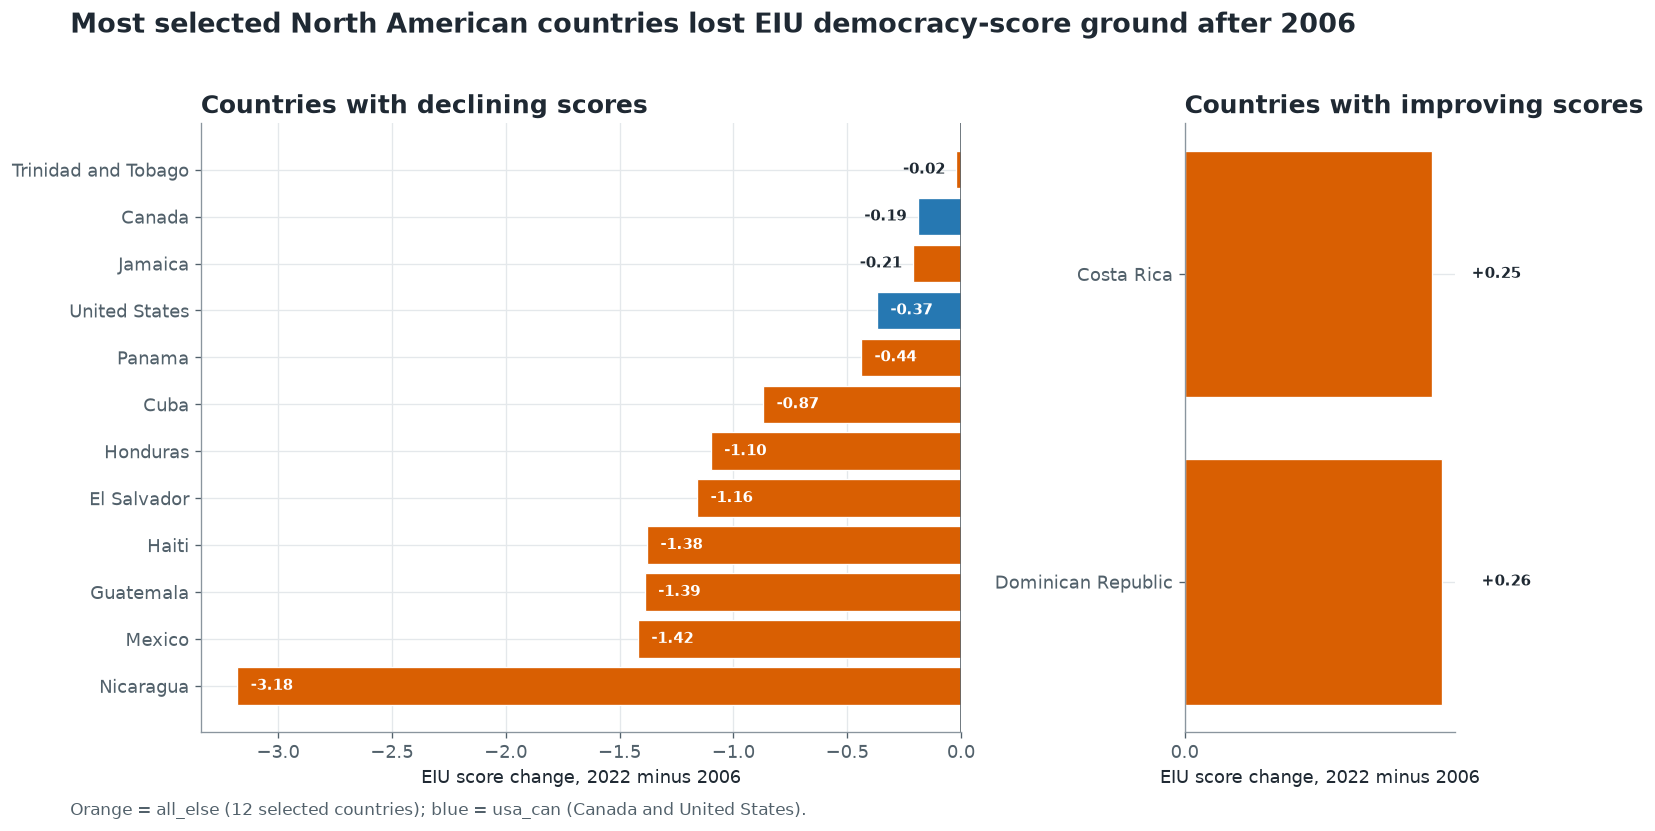

Saved: figures/don_north_america_score_change_2006_2022.png


In [7]:
plot_data = country_split.with_columns(
    pl.when(pl.col("group") == "all_else").then(pl.lit(ALL_ELSE)).otherwise(pl.lit(USA_CAN)).alias("color")
)
neg_plot = plot_data.filter(pl.col("delta_06_22") < 0).sort("delta_06_22")
pos_plot = plot_data.filter(pl.col("delta_06_22") > 0).sort("delta_06_22", descending=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={"width_ratios": [4.5, 1.6]})
for ax, frame, title in zip(axes, [neg_plot, pos_plot], ["Countries with declining scores", "Countries with improving scores"]):
    names = frame["Entity"].to_list()
    values = frame["delta_06_22"].to_list()
    colors = frame["color"].to_list()
    bars = ax.barh(names, values, color=colors, edgecolor="white", linewidth=0.8)
    ax.axvline(0, color="#59636a", linewidth=1)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel("EIU score change, 2022 minus 2006")
    ax.xaxis.set_major_locator(plt.MultipleLocator(0.5))
    for bar, value in zip(bars, values):
        y = bar.get_y() + bar.get_height() / 2
        if value <= -0.35:
            ax.text(value + 0.06, y, f"{value:+.2f}", va="center", ha="left", fontsize=9, color="white", fontweight="bold")
        elif value < 0:
            ax.text(value - 0.05, y, f"{value:+.2f}", va="center", ha="right", fontsize=9, color=INK, fontweight="bold")
        else:
            ax.text(value + 0.04, y, f"{value:+.2f}", va="center", ha="left", fontsize=9, color=INK, fontweight="bold")

fig.suptitle("Most selected North American countries lost EIU democracy-score ground after 2006", x=0.05, ha="left", y=1.02, fontsize=16, fontweight="bold")
fig.text(0.05, -0.01, "Orange = all_else (12 selected countries); blue = usa_can (Canada and United States).", color=MUTED, fontsize=10)
fig.tight_layout()
figure_path = FIGS / "don_north_america_score_change_2006_2022.png"
fig.savefig(figure_path, bbox_inches="tight", dpi=200)
plt.show()
print(f"Saved: {figure_path}")

## Interpretation and limits

The `all_else` countries’ mean endpoint change is more negative than the `usa_can` mean, and the difference is concentrated after 2014. The leave-one-country-out range shows that the average decline remains negative even when any one of the 12 countries is omitted. This does not show that geography, any policy, or an event caused the difference: the groups are deliberate geographic selections; scores are country-level EIU measures; and the panel has no 2007 or 2009 observations. The analysis describes score movement only and does not explain its causes.

In [8]:
all_else_summary = group_summary.filter(pl.col("group") == "all_else").row(0, named=True)
usa_can_summary = group_summary.filter(pl.col("group") == "usa_can").row(0, named=True)
print(
    f"Finding: all_else mean change = {all_else_summary['mean_delta_06_22']:.2f}; "
    f"usa_can mean change = {usa_can_summary['mean_delta_06_22']:.2f}.\n"
    f"Early (2006–2014): {all_else_summary['mean_delta_06_14']:.2f} vs {usa_can_summary['mean_delta_06_14']:.2f}; "
    f"late (2014–2022): {all_else_summary['mean_delta_14_22']:.2f} vs {usa_can_summary['mean_delta_14_22']:.2f}.\n"
    f"Sensitivity range after omitting one all_else country: {loo_min:.2f} to {loo_max:.2f}."
)

largest_negative = (
    country_split.filter(pl.col("delta_06_22") < 0)
    .sort("delta_06_22")
    .head(5)
    .select("Entity", "Code", "group", "delta_06_22")
)
print("\nFive countries with the largest negative endpoint deltas:")
print(largest_negative)

Finding: all_else mean change = -0.89; usa_can mean change = -0.28.
Early (2006–2014): -0.08 vs -0.05; late (2014–2022): -0.81 vs -0.23.
Sensitivity range after omitting one all_else country: -0.99 to -0.68.

Five countries with the largest negative endpoint deltas:
shape: (5, 4)
┌─────────────┬──────┬──────────┬─────────────┐
│ Entity      ┆ Code ┆ group    ┆ delta_06_22 │
│ ---         ┆ ---  ┆ ---      ┆ ---         │
│ str         ┆ str  ┆ str      ┆ f64         │
╞═════════════╪══════╪══════════╪═════════════╡
│ Nicaragua   ┆ NIC  ┆ all_else ┆ -3.18       │
│ Mexico      ┆ MEX  ┆ all_else ┆ -1.42       │
│ Guatemala   ┆ GTM  ┆ all_else ┆ -1.39       │
│ Haiti       ┆ HTI  ┆ all_else ┆ -1.38       │
│ El Salvador ┆ SLV  ┆ all_else ┆ -1.16       │
└─────────────┴──────┴──────────┴─────────────┘


# P2: "What was going on there?": Contextualizing the lowest scores

## Question, scope, and evidence standard

This section asks what documented political or institutional developments coincided with the sharpest EIU score losses among the five countries identified above. It does **not** estimate causal effects. Events are selected only after a reproducible rule identifies each country's two largest declines between observations exactly one calendar year apart; the 2006–2008 and 2008–2010 gaps are excluded from that ranking.

Interpretations use three labels:

- **Direct:** EIU explicitly connects the development to its score assessment.
- **Triangulated:** an authoritative event source and an independent democracy component move in a consistent direction, without proving causation.
- **Context only:** the timing is relevant, but the available evidence is insufficient to connect the event to the score.

The source hierarchy is EIU reports for the index's own interpretation, OAS/IACHR reports for institutional chronology, and V-Dem v13 for a separate expert-coded measurement check. Later retrospective sources are labeled rather than treated as contemporaneous evidence.

In [9]:
# Preserve the P1 ranking as the selection rule so contextual research cannot
# retroactively choose countries that best fit an event narrative.
focus_order = largest_negative.with_row_index("decline_rank", offset=1)
focus_codes = focus_order["Code"].to_list()

focus_series = (
    eiu.filter(pl.col("Code").is_in(focus_codes) & (pl.col("Year") <= 2022))
    .select("Entity", "Code", "Year", pl.col("Democracy score").alias("score"))
    .sort("Code", "Year")
    .with_columns(
        pl.col("Year").shift(1).over("Code").alias("previous_year"),
        pl.col("score").shift(1).over("Code").alias("previous_score"),
    )
    .with_columns(
        (pl.col("Year") - pl.col("previous_year")).alias("year_gap"),
        (pl.col("score") - pl.col("previous_score")).alias("score_delta"),
    )
)

# Only one-calendar-year comparisons can be read as annual breaks; this prevents
# the missing 2007 and 2009 observations from being mistaken for single-year change.
adjacent_changes = focus_series.filter(pl.col("year_gap") == 1)
nonannual_gaps = focus_series.filter(pl.col("year_gap") > 1)

# Taking two episodes per country keeps the evidence review balanced across the
# five selected cases instead of letting the longest or noisiest series dominate.
top_two_drops = (
    adjacent_changes.sort("Code", "score_delta")
    .group_by("Code", maintain_order=True)
    .head(2)
    .join(focus_order.select("Code", "decline_rank"), on="Code", how="left")
    .sort("decline_rank", "score_delta")
    .select(
        "decline_rank", "Entity", "Code", "previous_year", "Year",
        "previous_score", "score", "score_delta",
    )
)

# These checks turn the stated selection rule into a reproducibility guardrail.
assert focus_order.height == 5
assert focus_order["Code"].to_list() == ["NIC", "MEX", "GTM", "HTI", "SLV"]
assert top_two_drops.height == 10
assert top_two_drops.select((pl.col("Year") - pl.col("previous_year") == 1).all()).item()
assert nonannual_gaps.select((pl.col("year_gap") == 2).all()).item()

print("Two largest declines between consecutive observed calendar years:")
print(top_two_drops)
print("\nExcluded from annual-drop ranking because these span two calendar years:")
print(nonannual_gaps.select("Entity", "Code", "previous_year", "Year", "year_gap", "score_delta"))

Two largest declines between consecutive observed calendar years:
shape: (10, 8)
┌──────────────┬─────────────┬──────┬───────────────┬──────┬────────────────┬───────┬─────────────┐
│ decline_rank ┆ Entity      ┆ Code ┆ previous_year ┆ Year ┆ previous_score ┆ score ┆ score_delta │
│ ---          ┆ ---         ┆ ---  ┆ ---           ┆ ---  ┆ ---            ┆ ---   ┆ ---         │
│ u32          ┆ str         ┆ str  ┆ i64           ┆ i64  ┆ f64            ┆ f64   ┆ f64         │
╞══════════════╪═════════════╪══════╪═══════════════╪══════╪════════════════╪═══════╪═════════════╡
│ 1            ┆ Nicaragua   ┆ NIC  ┆ 2017          ┆ 2018 ┆ 4.66           ┆ 3.63  ┆ -1.03       │
│ 1            ┆ Nicaragua   ┆ NIC  ┆ 2020          ┆ 2021 ┆ 3.6            ┆ 2.69  ┆ -0.91       │
│ 2            ┆ Mexico      ┆ MEX  ┆ 2020          ┆ 2021 ┆ 6.07           ┆ 5.57  ┆ -0.5        │
│ 2            ┆ Mexico      ┆ MEX  ┆ 2021          ┆ 2022 ┆ 5.57           ┆ 5.25  ┆ -0.32       │
│ 3            ┆ Gu

## Country dossiers

**Nicaragua.** The largest breaks are 2017–2018 (−1.03) and 2020–2021 (−0.91). The IACHR documents repression following the April 2018 protests, closure of media and civic organizations, weakened separation of powers, and the arbitrary detention of prospective opposition candidates before the 2021 election. EIU's regional retrospective says Nicaragua became an autocracy in 2018. This is strong temporal and institutional alignment, but the reports do not identify how much each development contributed to the numeric score. Sources: [IACHR 2021 country report](https://www.oas.org/en/iachr/reports/pdfs/2021_Nicaragua-EN.pdf) and [EIU Democracy Index 2022](https://www.eiu.com/n/wp-content/uploads/2023/02/Democracy-Index-2022.pdf).

**Mexico.** The largest consecutive-year losses are 2020–2021 (−0.50) and 2021–2022 (−0.32). EIU directly attributes the 2022 downgrade to attacks on checks and balances and electoral authorities, threats to media freedom, and the expanded role of the armed forces. The IACHR separately reported continued militarization, disappearances, homicides, and danger to journalists. V-Dem provides an important counterpoint below: its clean-elections estimate rises slightly after 2014 even while its executive-constraint measures decline. Sources: [EIU Democracy Index 2022, pp. 44–45](https://www.eiu.com/n/wp-content/uploads/2023/02/Democracy-Index-2022.pdf) and [IACHR 2022 Mexico follow-up](https://www.oas.org/en/iachr/docs/annual/2022/Chapters/14-IA2022_Cap_5_MX_EN.pdf).

**Guatemala.** The two largest consecutive-year losses are 2020–2021 (−0.35) and 2018–2019 (−0.34), within an uninterrupted slide from 2017 through 2021. The IACHR records the 2019 termination of CICIG after efforts to weaken it, followed by intensified interference with judicial independence and the 2021 dismissal of the head of the Special Prosecutor against Impunity. Because the EIU report does not directly assign Guatemala's numeric changes to those events, this remains triangulated context rather than an EIU-stated explanation. Sources: [IACHR January 2019 statement](https://www.oas.org/en/iachr/media_center/PReleases/2019/007.asp) and [IACHR 2021 Guatemala chapter](https://www.oas.org/en/iachr/docs/annual/2021/Chapters/IA2021cap4B.Guatemala-en.pdf).

**Haiti.** The sharpest losses occur in 2020–2021 (−0.74) and 2021–2022 (−0.67). The IACHR describes an institutional vacuum after legislative mandates expired, government by decree, the July 2021 assassination of President Jovenel Moïse, delayed elections, and escalating armed-group violence. EIU directly links the 2022 downgrade to loss of state control and failure to call elections. The 2018 score increase from 4.03 to 4.91 is a counterexample to a simple monotonic-decline story and is not assigned an explanation here. Sources: [IACHR January 2023 report release](https://www.oas.org/en/iachr/jsForm/?File=%2Fen%2Fiachr%2Fmedia_center%2Fpreleases%2F2023%2F001.asp) and [EIU Democracy Index 2022](https://www.eiu.com/n/wp-content/uploads/2023/02/Democracy-Index-2022.pdf).

**El Salvador.** The largest losses are 2021–2022 (−0.66) and 2017–2018 (−0.47). EIU directly connects the 2022 fall to weakened checks and balances, the pursuit of consecutive re-election, the state of emergency, and restrictions affecting civil liberties and media. The IACHR separately documents the 2021 removal of Constitutional Chamber judges and the attorney general and worsening conditions for expression during 2022. The sources reviewed do not provide a comparably specific explanation for the 2018 drop, so that episode is retained as **context only/unexplained** rather than reverse-engineered from later events. Sources: [OAS May 2021 statement](https://www.oas.org/en/media_center/press_release.asp?sCodigo=E-044%2F21), [IACHR 2022 freedom-of-expression chapter](https://www.oas.org/en/iachr/expression/reports/IA2022ENG.pdf), and [EIU Democracy Index 2022](https://www.eiu.com/n/wp-content/uploads/2023/02/Democracy-Index-2022.pdf).

In [10]:
# Record the evidence decisions separately from the EIU data so each narrative
# claim, source set, and counterpoint remains inspectable rather than embedded in prose.
context_records = [
    {
        "Code": "NIC", "period_end": 2018,
        "documented_context": "Repression after April protests; civic and media spaces closed",
        "dimensions": "civil liberties; expression; executive constraints",
        "evidence_grade": "Triangulated", "source_ids": "IACHR-2021; EIU-2022",
        "counterpoint": "Longer concentration-of-power process predates 2018",
    },
    {
        "Code": "NIC", "period_end": 2021,
        "documented_context": "Opposition candidates detained before an election lacking plural competition",
        "dimensions": "clean elections; opposition; executive constraints",
        "evidence_grade": "Triangulated", "source_ids": "IACHR-2021; EIU-2022",
        "counterpoint": "EIU report does not allocate the numeric drop across mechanisms",
    },
    {
        "Code": "MEX", "period_end": 2021,
        "documented_context": "Backsliding concerns involving checks, electoral authorities, media, and military role",
        "dimensions": "executive constraints; expression; state security",
        "evidence_grade": "Triangulated", "source_ids": "EIU-2022; IACHR-2022",
        "counterpoint": "V-Dem clean-elections estimate does not decline after 2014",
    },
    {
        "Code": "MEX", "period_end": 2022,
        "documented_context": "Pressure on electoral authority and checks; expanded military role; journalist killings",
        "dimensions": "executive constraints; expression; electoral administration",
        "evidence_grade": "Direct", "source_ids": "EIU-2022; IACHR-2022",
        "counterpoint": "Sources overlap conceptually with the democracy outcome",
    },
    {
        "Code": "GTM", "period_end": 2019,
        "documented_context": "CICIG mandate ended after government efforts to weaken the commission",
        "dimensions": "judicial constraints; anti-corruption institutions",
        "evidence_grade": "Triangulated", "source_ids": "IACHR-2019; IACHR-2021",
        "counterpoint": "No EIU statement assigns this event a numeric contribution",
    },
    {
        "Code": "GTM", "period_end": 2021,
        "documented_context": "Intensified judicial interference and removal of anti-impunity prosecutor",
        "dimensions": "judicial independence; rule of law",
        "evidence_grade": "Triangulated", "source_ids": "IACHR-2021; V-Dem-v13",
        "counterpoint": "The decline is gradual rather than a single-event break",
    },
    {
        "Code": "HTI", "period_end": 2021,
        "documented_context": "Legislative vacuum, government by decree, and assassination of President Moïse",
        "dimensions": "elections; functioning government; state capacity",
        "evidence_grade": "Triangulated", "source_ids": "IACHR-2023; EIU-2022",
        "counterpoint": "Multiple simultaneous crises prevent mechanism isolation",
    },
    {
        "Code": "HTI", "period_end": 2022,
        "documented_context": "Elections not called while armed groups gained territorial control",
        "dimensions": "clean elections; functioning government; state capacity",
        "evidence_grade": "Direct", "source_ids": "EIU-2022; IACHR-2023",
        "counterpoint": "The index combines democracy and government-functioning judgments",
    },
    {
        "Code": "SLV", "period_end": 2018,
        "documented_context": "No sufficiently specific period-matched explanation located",
        "dimensions": "unresolved",
        "evidence_grade": "Context only", "source_ids": "EIU series",
        "counterpoint": "Do not project the later Bukele-era explanation backward",
    },
    {
        "Code": "SLV", "period_end": 2022,
        "documented_context": "Emergency restrictions, weakened checks, re-election move, and media constraints",
        "dimensions": "executive constraints; civil liberties; expression",
        "evidence_grade": "Direct", "source_ids": "EIU-2022; OAS-2021; IACHR-2022",
        "counterpoint": "Lower homicide levels are a simultaneous favorable outcome",
    },
]

# Join to observed change data instead of copying values into the dossier, keeping
# the contextual labels tied to the same reproducible periods selected above.
context_matrix = (
    pl.DataFrame(context_records)
    .join(
        adjacent_changes.select(
            "Entity", "Code", pl.col("Year").alias("period_end"),
            "previous_year", "previous_score", "score", "score_delta",
        ),
        on=["Code", "period_end"],
        how="left",
        validate="1:1",
    )
    .join(focus_order.select("Code", "decline_rank"), on="Code", how="left")
    .sort("decline_rank", "score_delta")
)

# Exact episode matching prevents post-hoc context from being attached to another
# year, while the grade check keeps all three stated evidence standards represented.
expected_periods = set(
    top_two_drops.select("Code", pl.col("Year").alias("period_end")).iter_rows()
)
assert set(context_matrix.select("Code", "period_end").iter_rows()) == expected_periods
assert context_matrix.select(pl.col("score_delta").is_not_null().all()).item()
assert context_matrix["evidence_grade"].value_counts().sort("evidence_grade").height == 3

print("Context matrix for the ten preselected decline episodes:")
print(
    context_matrix.select(
        "Entity", "previous_year", "period_end", "score_delta",
        "documented_context", "dimensions", "evidence_grade", "source_ids",
    )
)
print("\nEvidence-grade counts:")
print(context_matrix.group_by("evidence_grade").len().sort("evidence_grade"))

Context matrix for the ten preselected decline episodes:
shape: (10, 8)
┌─────────────┬───────────────┬────────────┬─────────────┬──────────────────────────────────┬────────────────────────┬────────────────┬────────────────────────┐
│ Entity      ┆ previous_year ┆ period_end ┆ score_delta ┆ documented_context               ┆ dimensions             ┆ evidence_grade ┆ source_ids             │
│ ---         ┆ ---           ┆ ---        ┆ ---         ┆ ---                              ┆ ---                    ┆ ---            ┆ ---                    │
│ str         ┆ i64           ┆ i64        ┆ f64         ┆ str                              ┆ str                    ┆ str            ┆ str                    │
╞═════════════╪═══════════════╪════════════╪═════════════╪══════════════════════════════════╪════════════════════════╪════════════════╪════════════════════════╡
│ Nicaragua   ┆ 2017          ┆ 2018       ┆ -1.03       ┆ Repression after April protest…  ┆ civil liberties;       ┆ Tria

## Optional EDA: independent component check

The contextual review suggests a focused check of electoral integrity, freedom of expression, and constraints on executive power. The analysis uses the official V-Dem Institute `vdemdata` package at tag **V13** (March 2023), which covers through 2022. The package's country-year data are pinned by URL and SHA-256 below; only the five countries and four prespecified indices are loaded into Python.

The four indices are [documented in the V-Dem v13 codebook](https://www.v-dem.net/documents/24/codebook_v13.pdf), range from 0 to 1, and run from lower to higher attainment:

- `v2xel_frefair`: clean elections.
- `v2x_freexp_altinf`: freedom of expression and alternative information.
- `v2x_jucon`: judicial constraints on the executive.
- `v2xlg_legcon`: legislative constraints on the executive.

The `codelow` and `codehigh` fields express coding uncertainty. The check calls a decline **clearly separated** only when the 2022 upper bound is below the 2014 lower bound. This is a deliberately conservative descriptive rule, not a confidence interval for the change and not a hypothesis test.

In [11]:
import hashlib
import io
import subprocess
import urllib.request


# Pin both location and content hash so the optional external check remains
# reproducible even if upstream data are later changed or silently replaced.
VDEM_URL = "https://raw.githubusercontent.com/vdeminstitute/vdemdata/V13/data/vdem.RData"
VDEM_SHA256 = "1e8749eed57bf4ce34356123dcc074c1e5be27887abf1803ff605bbe187e68a8"
# Cache outside the repository: the source is large and is contextual evidence,
# not an input to the project's core EIU/HDI data build.
VDEM_CACHE = Path("/tmp/vdem_v13.RData")
VDEM_CODES = ["NIC", "MEX", "GTM", "HTI", "SLV"]
VDEM_INDICATORS = {
    "v2xel_frefair": "Clean elections",
    "v2x_freexp_altinf": "Freedom of expression",
    "v2x_jucon": "Judicial constraints",
    "v2xlg_legcon": "Legislative constraints",
}


def file_sha256(path: Path) -> str:
    """Hash the cached source in blocks so provenance validation scales to large files."""
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


if not VDEM_CACHE.exists():
    VDEM_CACHE.parent.mkdir(exist_ok=True)
    partial = VDEM_CACHE.with_suffix(".RData.part")
    # Write then rename only after the transfer completes, avoiding reuse of a
    # partially downloaded file after an interrupted notebook run.
    with urllib.request.urlopen(VDEM_URL) as response, partial.open("wb") as output:
        while block := response.read(1024 * 1024):
            output.write(block)
    partial.replace(VDEM_CACHE)

assert file_sha256(VDEM_CACHE) == VDEM_SHA256, "Unexpected V-Dem v13 source hash"

# Extract only the prespecified countries, years, indices, and uncertainty bounds
# in R; this avoids loading V-Dem's full RData object into the Python analysis.
value_columns = []
for indicator in VDEM_INDICATORS:
    value_columns.extend(
        [indicator, f"{indicator}_codelow", f"{indicator}_codehigh"]
    )
r_columns = ["country_name", "country_text_id", "year", *value_columns]
r_path = VDEM_CACHE.resolve().as_posix().replace('"', '\\"')
r_script = f"""
load("{r_path}")
keep <- c({", ".join(repr(column) for column in r_columns)})
focus <- vdem[
    vdem$country_text_id %in% c("NIC", "MEX", "GTM", "HTI", "SLV") &
    vdem$year >= 2006 & vdem$year <= 2022,
    keep
]
write.csv(focus, stdout(), row.names=FALSE)
"""
result = subprocess.run(
    ["Rscript", "-e", r_script],
    check=True,
    capture_output=True,
    text=True,
)
vdem_focus = pl.read_csv(io.StringIO(result.stdout))

# Validate the expected rectangular panel and scale to detect a changed schema,
# wrong country IDs, or unavailable uncertainty bounds before interpretation.
assert vdem_focus.height == 85
assert vdem_focus.select(pl.struct("country_text_id", "year").n_unique()).item() == 85
assert set(vdem_focus["country_text_id"].unique()) == set(VDEM_CODES)
for column in value_columns:
    assert vdem_focus[column].null_count() == 0
    assert vdem_focus.select(pl.col(column).is_between(0, 1, closed="both").all()).item()

print(
    f"Validated {vdem_focus.height} V-Dem v13 country-year rows "
    f"({vdem_focus['year'].min()}–{vdem_focus['year'].max()}) "
    f"from source SHA-256 {VDEM_SHA256[:12]}…"
)

Validated 85 V-Dem v13 country-year rows (2006–2022) from source SHA-256 1e8749eed57b…


### How to read the component-change table

Each row is one **country × V-Dem component**. The four components are separate 0–1 indices: higher values indicate stronger conditions on that component, and lower values indicate weaker conditions. For example, a fall in *Judicial constraints* means V-Dem's expert-coded estimate of constraints on the executive was lower—not that the country lost a percentage of democracy, or a number of EIU-score points.

- **estimate_2006, estimate_2014, and estimate_2022** are V-Dem's point estimates in those years. Read them chiefly within the same component over time; the components measure different concepts, so their raw levels should not be treated as directly interchangeable.
- **delta_06_14, delta_14_22, and delta_06_22** are later estimate minus earlier estimate. A negative value means the point estimate fell. For instance, −0.20 for delta_14_22 means a decrease of 0.20 on that component's 0–1 scale from 2014 to 2022.
- **low_* and high_*** are V-Dem's coding-uncertainty bounds, not a confidence interval calculated by this notebook.
- **clearly_separated_decline_14_22 = True** is a deliberately strict signal: even the highest plausible 2022 value is below the lowest plausible 2014 value. A value of **False** does *not* show stability or improvement; it means the bounds overlap, so this conservative rule cannot distinguish the change from coding uncertainty.

The table is an independent descriptive check of institutional dimensions, not evidence that a component caused an EIU score change. The narrative emphasizes the 2014–2022 columns because that later period contains much of the focal countries' endpoint decline.

In [12]:
# Reshape the four prespecified components to a country-component panel so
# early, late, and full-period comparisons use identical indicator definitions.
vdem_long_rows = []
for row in vdem_focus.filter(pl.col("year").is_in([2006, 2014, 2022])).iter_rows(named=True):
    for indicator, label in VDEM_INDICATORS.items():
        vdem_long_rows.append(
            {
                "country": row["country_name"],
                "Code": row["country_text_id"],
                "year": row["year"],
                "indicator": indicator,
                "indicator_label": label,
                "estimate": row[indicator],
                "low": row[f"{indicator}_codelow"],
                "high": row[f"{indicator}_codehigh"],
            }
        )

vdem_long = pl.DataFrame(vdem_long_rows)
vdem_comparison = (
    vdem_long.pivot(
        on="year",
        index=["country", "Code", "indicator", "indicator_label"],
        values=["estimate", "low", "high"],
    )
    .with_columns(
        (pl.col("estimate_2014") - pl.col("estimate_2006")).alias("delta_06_14"),
        (pl.col("estimate_2022") - pl.col("estimate_2014")).alias("delta_14_22"),
        (pl.col("estimate_2022") - pl.col("estimate_2006")).alias("delta_06_22"),
        # Require non-overlapping coding bounds for a deliberately conservative
        # descriptive signal; point-estimate direction alone is not enough.
        (pl.col("high_2022") < pl.col("low_2014")).alias("clearly_separated_decline_14_22"),
        (pl.col("low_2022") > pl.col("high_2014")).alias("clearly_separated_increase_14_22"),
    )
    .join(focus_order.select("Code", "decline_rank"), on="Code", how="left")
    .sort("decline_rank", "indicator_label")
)

# Verify full country-component coverage and rule out a logically impossible
# simultaneous classification as both a clear decline and clear increase.
assert vdem_comparison.height == 20
assert vdem_comparison.select(
    (~(pl.col("clearly_separated_decline_14_22") & pl.col("clearly_separated_increase_14_22"))).all()
).item()

late_decline_count = vdem_comparison.select((pl.col("delta_14_22") < 0).sum()).item()
clear_late_decline_count = vdem_comparison["clearly_separated_decline_14_22"].sum()
country_component_summary = (
    vdem_comparison.group_by("country")
    .agg(
        (pl.col("delta_14_22") < 0).sum().alias("components_with_lower_2022_estimate"),
        pl.col("clearly_separated_decline_14_22").sum().alias("clearly_separated_declines"),
    )
    .sort("country")
)

print("V-Dem component changes; negative values indicate lower 2022 estimates:")
print(
    vdem_comparison.select(
        "country", "indicator_label", "estimate_2006", "estimate_2014", "estimate_2022",
        "delta_06_14", "delta_14_22", "delta_06_22",
        "low_2014", "high_2014", "low_2022", "high_2022",
        "clearly_separated_decline_14_22",
    ).with_columns(pl.selectors.numeric().round(3))
)
print(
    f"\nPost-2014 direction: {late_decline_count} of 20 country-component estimates declined; "
    f"{clear_late_decline_count} of 20 met the conservative non-overlap rule."
)
print(country_component_summary)

V-Dem component changes; negative values indicate lower 2022 estimates:
shape: (20, 13)
┌─────────────┬─────────────────────────┬───────────────┬───────────────┬───┬───────────┬──────────┬───────────┬─────────────────────────────────┐
│ country     ┆ indicator_label         ┆ estimate_2006 ┆ estimate_2014 ┆ … ┆ high_2014 ┆ low_2022 ┆ high_2022 ┆ clearly_separated_decline_14_2… │
│ ---         ┆ ---                     ┆ ---           ┆ ---           ┆   ┆ ---       ┆ ---      ┆ ---       ┆ ---                             │
│ str         ┆ str                     ┆ f64           ┆ f64           ┆   ┆ f64       ┆ f64      ┆ f64       ┆ bool                            │
╞═════════════╪═════════════════════════╪═══════════════╪═══════════════╪═══╪═══════════╪══════════╪═══════════╪═════════════════════════════════╡
│ Nicaragua   ┆ Clean elections         ┆ 0.556         ┆ 0.288         ┆ … ┆ 0.387     ┆ 0.086    ┆ 0.236     ┆ false                           │
│ Nicaragua   ┆ Freedom of exp

### Visual reference: 2014-to-2022 component movement

The figure below turns the table into four dumbbell panels. In each panel, a country’s blue filled dot is its 2014 estimate and its orange open dot is its 2022 estimate; the connecting line shows the direction and size of movement on the same 0–1 component scale. The number at right expresses that movement in **percentage points of the full V-Dem scale**—for example, \(−0.20\) is a 20-point movement on a 0–1 scale, not a 20% fall in democracy.

Faint horizontal bands are V-Dem’s coding bounds. A dagger (†) identifies cases where the 2022 upper bound is below the 2014 lower bound, the pre-specified conservative “clearly separated decline” rule. The visualization is descriptive and does not translate V-Dem values into EIU points or make causal claims.

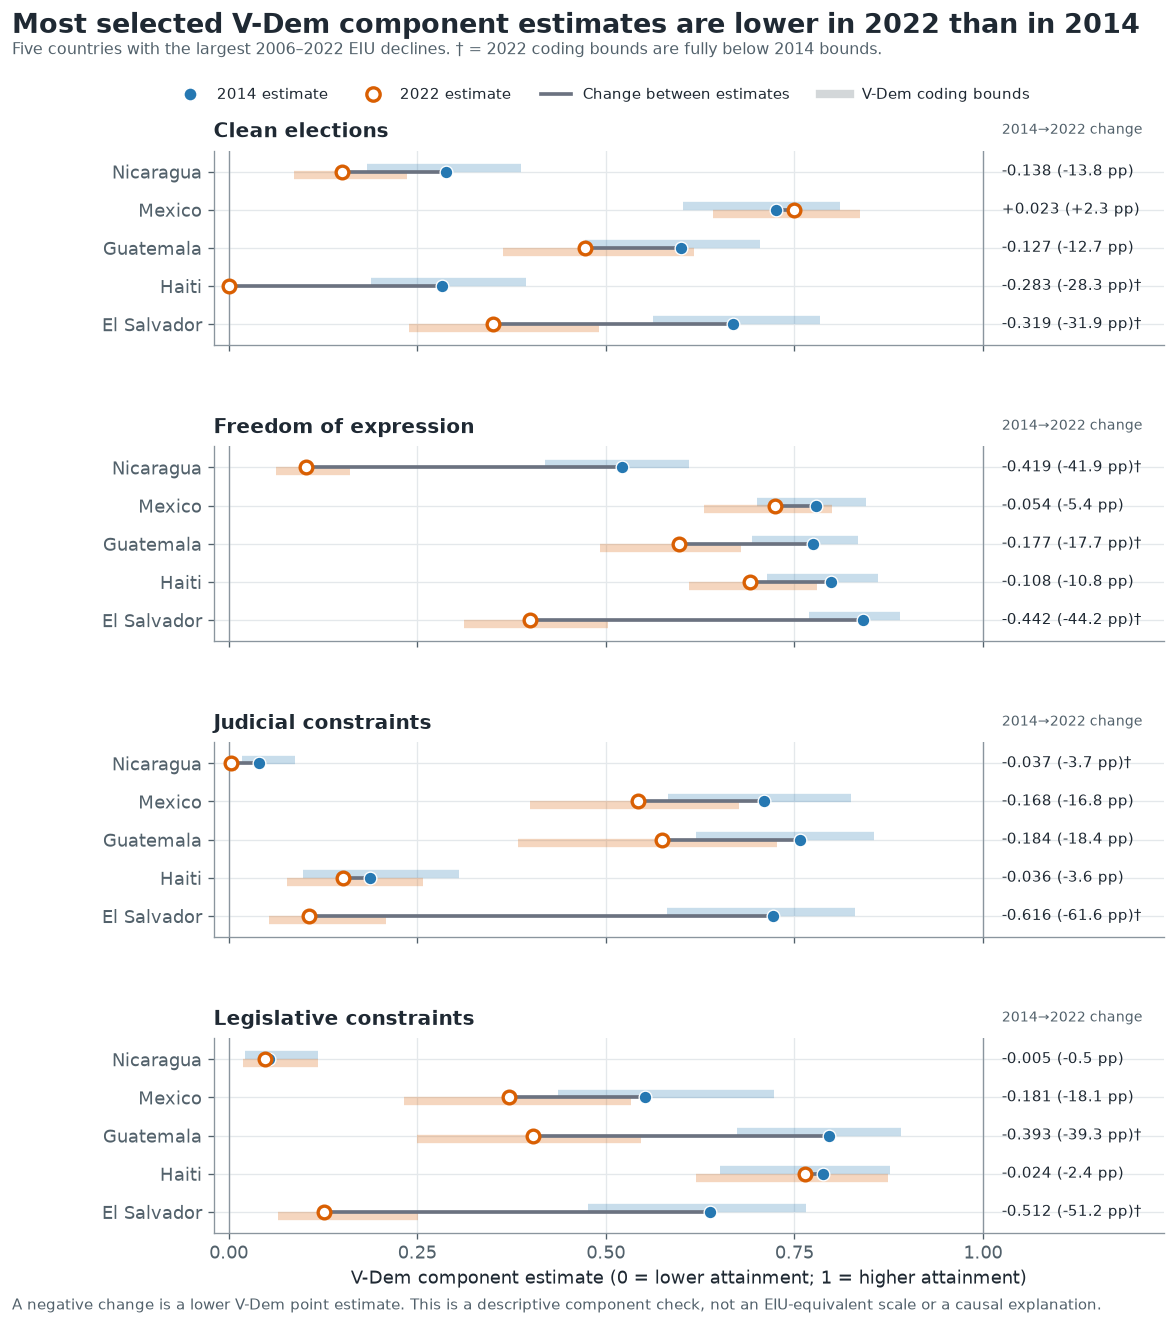

Saved figure: figures/don_vdem_component_changes_2014_2022.png (359,353 bytes)


In [13]:
from matplotlib.lines import Line2D

# A shared 0–1 axis lets readers judge each change against the full component
# range, while separate panels avoid implying that differently defined components
# are interchangeable measures of one common quantity.
component_order = list(VDEM_INDICATORS.items())
country_order = (
    focus_order.select("Entity", "Code", "decline_rank")
    .sort("decline_rank")
)

fig, axes = plt.subplots(
    nrows=len(component_order),
    ncols=1,
    figsize=(12, 11),
    sharex=True,
    constrained_layout=False,
)

for ax, (indicator, label) in zip(axes, component_order):
    component_data = (
        vdem_comparison
        .filter(pl.col("indicator") == indicator)
        .join(country_order, on=["Code", "decline_rank"], how="inner")
        .sort("decline_rank")
    )
    y_positions = list(range(component_data.height - 1, -1, -1))

    for y, row in zip(y_positions, component_data.iter_rows(named=True)):
        # Draw coding bounds separately for each endpoint so visual comparison
        # includes the uncertainty used by the conservative decline rule.
        ax.hlines(y + 0.10, row["low_2014"], row["high_2014"],
                  color="#2678b2", linewidth=5, alpha=0.25, zorder=1)
        ax.hlines(y - 0.10, row["low_2022"], row["high_2022"],
                  color="#d95f02", linewidth=5, alpha=0.25, zorder=1)

        ax.plot(
            [row["estimate_2014"], row["estimate_2022"]], [y, y],
            color="#6b7280", linewidth=2.2, zorder=2,
        )
        ax.scatter(
            row["estimate_2014"], y, s=58, color="#2678b2",
            edgecolor="white", linewidth=0.8, zorder=3,
        )
        ax.scatter(
            row["estimate_2022"], y, s=58, facecolor="white",
            edgecolor="#d95f02", linewidth=2, zorder=4,
        )

        # Percentage points make the 0–1 movement more concrete without
        # misrepresenting it as a percentage change or an EIU-score change.
        separation_marker = "†" if row["clearly_separated_decline_14_22"] else ""
        ax.text(
            1.025, y,
            f"{row['delta_14_22']:+.3f} ({row['delta_14_22'] * 100:+.1f} pp){separation_marker}",
            va="center", ha="left", fontsize=9, color=INK,
        )

    ax.set_title(label, loc="left", fontsize=12, fontweight="bold", pad=8)
    ax.set_yticks(y_positions, component_data["country"].to_list())
    ax.set_ylim(-0.55, component_data.height - 0.45)
    ax.set_xlim(-0.02, 1.24)
    ax.axvline(0, color="#8a959e", linewidth=0.8)
    ax.axvline(1, color="#8a959e", linewidth=0.8)
    ax.text(
        1.025, component_data.height - 0.10,
        "2014→2022 change", ha="left", va="bottom",
        fontsize=8.5, color=MUTED,
    )

axes[-1].set_xticks([0, 0.25, 0.50, 0.75, 1.00])
axes[-1].set_xlabel("V-Dem component estimate (0 = lower attainment; 1 = higher attainment)")

legend_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#2678b2",
           markeredgecolor="white", markersize=8, label="2014 estimate"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
           markeredgecolor="#d95f02", markeredgewidth=2, markersize=8, label="2022 estimate"),
    Line2D([0], [0], color="#6b7280", linewidth=2.2, label="Change between estimates"),
    Line2D([0], [0], color="#52616b", linewidth=5, alpha=0.25, label="V-Dem coding bounds"),
]
fig.legend(
    handles=legend_handles, ncol=4, loc="upper center",
    bbox_to_anchor=(0.49, 0.948), frameon=False, fontsize=9,
)
fig.suptitle(
    "Most selected V-Dem component estimates are lower in 2022 than in 2014",
    x=0.08, y=0.995, ha="left", fontsize=16, fontweight="bold", color=INK,
)
fig.text(
    0.08, 0.963,
    "Five countries with the largest 2006–2022 EIU declines. "
    "† = 2022 coding bounds are fully below 2014 bounds.",
    ha="left", fontsize=9.5, color=MUTED,
)
fig.text(
    0.08, 0.012,
    "A negative change is a lower V-Dem point estimate. This is a descriptive "
    "component check, not an EIU-equivalent scale or a causal explanation.",
    ha="left", fontsize=8.8, color=MUTED,
)
fig.subplots_adjust(left=0.22, right=0.88, top=0.89, bottom=0.07, hspace=0.52)

vdem_figure_path = FIGS / "don_vdem_component_changes_2014_2022.png"
fig.savefig(vdem_figure_path, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()

assert vdem_figure_path.exists() and vdem_figure_path.stat().st_size > 0
print(f"Saved figure: {vdem_figure_path} ({vdem_figure_path.stat().st_size:,} bytes)")

## Matched-year EIU/V-Dem correlation check

This check asks whether country-year movements in the four V-Dem components are associated with the EIU democracy score for the same country and year. The join keeps only country-years present in **both** datasets, so EIU's missing 2007 and 2009 observations are excluded rather than silently filled.

The pooled matrix combines differences **between countries** with changes **within countries**. To show how much the result depends on those country-level baselines, the code also prints a within-country matrix after subtracting each country's own mean from every variable. Both are descriptive correlations: the five countries were selected for large EIU declines, the observations repeat countries over time, and the two expert-coded projects measure overlapping democratic concepts.

In [14]:
import numpy as np

# Join on country-year rather than position so only genuinely comparable
# observations enter the matrix; this also makes the missing EIU years visible.
eiu_focus_panel = (
    eiu.filter(
        pl.col("Code").is_in(focus_codes)
        & (pl.col("Year") >= 2006)
        & (pl.col("Year") <= 2022)
    )
    .select(
        "Entity", "Code", "Year",
        pl.col("Democracy score").alias("eiu_score"),
    )
)
vdem_panel = vdem_focus.select(
    pl.col("country_text_id").alias("Code"),
    pl.col("year").alias("Year"),
    *VDEM_INDICATORS.keys(),
)
matched_panel = (
    eiu_focus_panel
    .join(vdem_panel, on=["Code", "Year"], how="inner", validate="1:1")
    .sort("Code", "Year")
)

correlation_columns = ["eiu_score", *VDEM_INDICATORS.keys()]
correlation_labels = [
    "EIU democracy score",
    *VDEM_INDICATORS.values(),
]

# The pooled matrix describes the overall association, but it includes
# persistent level differences between the five selected countries.
def make_correlation_table(frame: pl.DataFrame) -> pl.DataFrame:
    values = frame.select(correlation_columns).to_numpy().astype(float)
    matrix = np.corrcoef(values, rowvar=False)
    return (
        pl.DataFrame(matrix, schema=correlation_labels)
        .with_columns(pl.Series("measure", correlation_labels))
        .select("measure", *correlation_labels)
    )


pooled_correlation = make_correlation_table(matched_panel)

# Demeaning by country removes each country's average level, giving a
# within-country check that is less driven by cross-country baselines.
within_country_panel = matched_panel.with_columns(
    [
        (pl.col(column) - pl.col(column).mean().over("Code")).alias(column)
        for column in correlation_columns
    ]
)
within_country_correlation = make_correlation_table(within_country_panel)

assert matched_panel.height == 75
assert matched_panel.select(pl.struct("Code", "Year").n_unique()).item() == 75
assert matched_panel["Code"].n_unique() == 5
assert matched_panel["Year"].n_unique() == 15
assert set(matched_panel["Year"].unique()) == (
    set(range(2006, 2023)) - {2007, 2009}
)

print(
    f"Matched {matched_panel.height} country-year rows across "
    f"{matched_panel['Code'].n_unique()} countries and "
    f"{matched_panel['Year'].n_unique()} shared years. "
    "The two level-correlation heatmaps appear below."
)

Matched 75 country-year rows across 5 countries and 15 shared years. The two level-correlation heatmaps appear below.


### Matched year-to-year change correlations

The level matrix can be high simply because some countries are generally high on both measures. This second check correlates **changes** instead: EIU score change with each V-Dem component change for the same country and consecutive shared years. It is closer to the question about whether declines move together, but it still does not establish causation and remains sensitive to the five-country selection.

In [15]:
# Restrict the change analysis to consecutive shared years so the missing
# 2007 and 2009 EIU observations do not become artificial annual changes.
change_panel = (
    matched_panel
    .sort("Code", "Year")
    .with_columns(
        pl.col("Year").shift(1).over("Code").alias("previous_year"),
        pl.col("eiu_score").shift(1).over("Code").alias("previous_eiu_score"),
        *[
            pl.col(indicator).shift(1).over("Code").alias(f"previous_{indicator}")
            for indicator in VDEM_INDICATORS
        ],
    )
    .with_columns(
        (pl.col("Year") - pl.col("previous_year")).alias("year_gap"),
        (pl.col("eiu_score") - pl.col("previous_eiu_score")).alias("eiu_delta"),
        *[
            (pl.col(indicator) - pl.col(f"previous_{indicator}")).alias(f"{indicator}_delta")
            for indicator in VDEM_INDICATORS
        ],
    )
    .filter(pl.col("year_gap") == 1)
)

change_columns = ["eiu_delta", *[f"{indicator}_delta" for indicator in VDEM_INDICATORS]]
change_labels = ["EIU score change", *VDEM_INDICATORS.values()]
change_values = change_panel.select(change_columns).to_numpy().astype(float)
change_matrix = np.corrcoef(change_values, rowvar=False)
change_correlation = (
    pl.DataFrame(change_matrix, schema=change_labels)
    .with_columns(pl.Series("measure", change_labels))
    .select("measure", *change_labels)
)

assert change_panel.height == 60
assert change_panel.select(pl.struct("Code", "Year").n_unique()).item() == 60
assert change_panel.select((pl.col("year_gap") == 1).all()).item()

print(
    f"Matched {change_panel.height} consecutive country-year changes "
    f"across {change_panel['Code'].n_unique()} countries "
    f"({change_panel['Year'].min()}–{change_panel['Year'].max()}). "
    "The change-correlation heatmap appears below."
)

Matched 60 consecutive country-year changes across 5 countries (2011–2022). The change-correlation heatmap appears below.


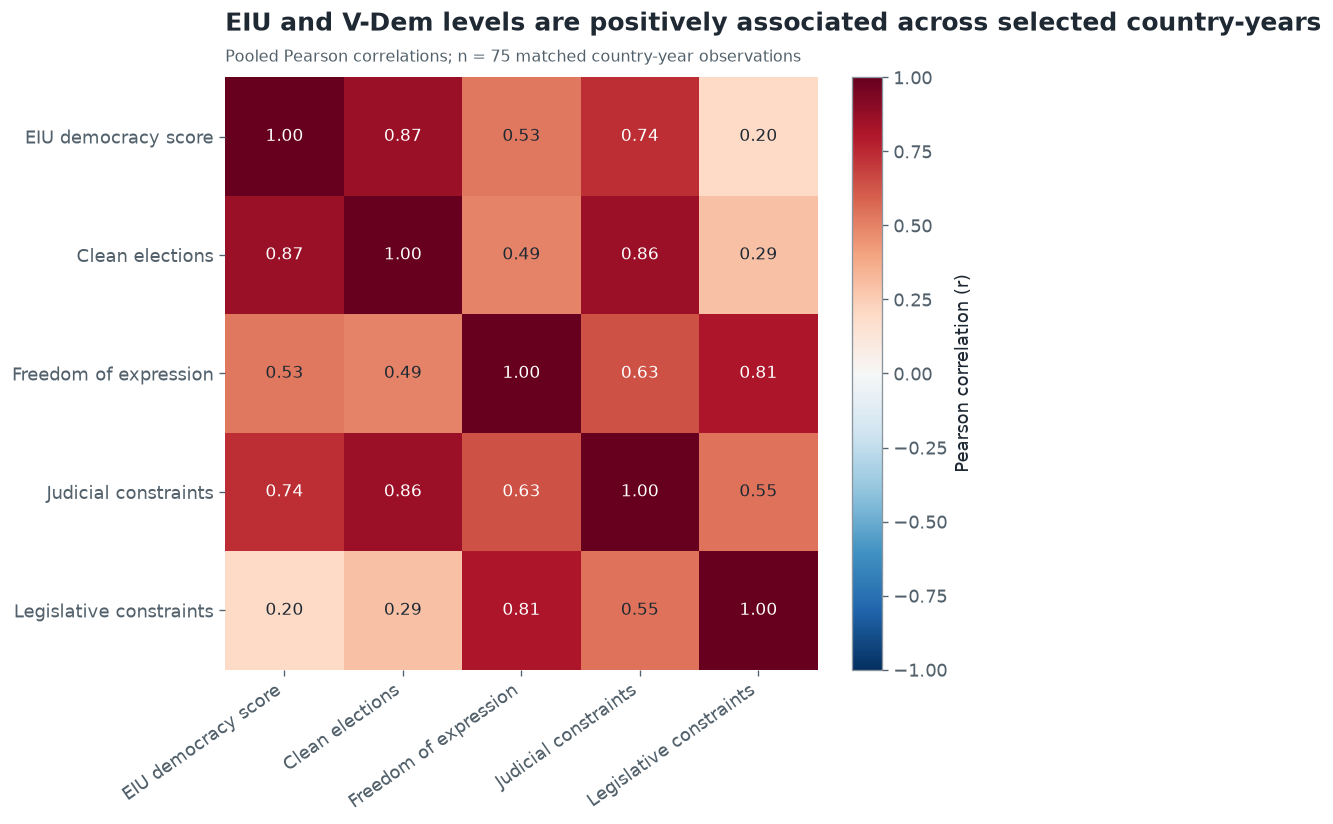

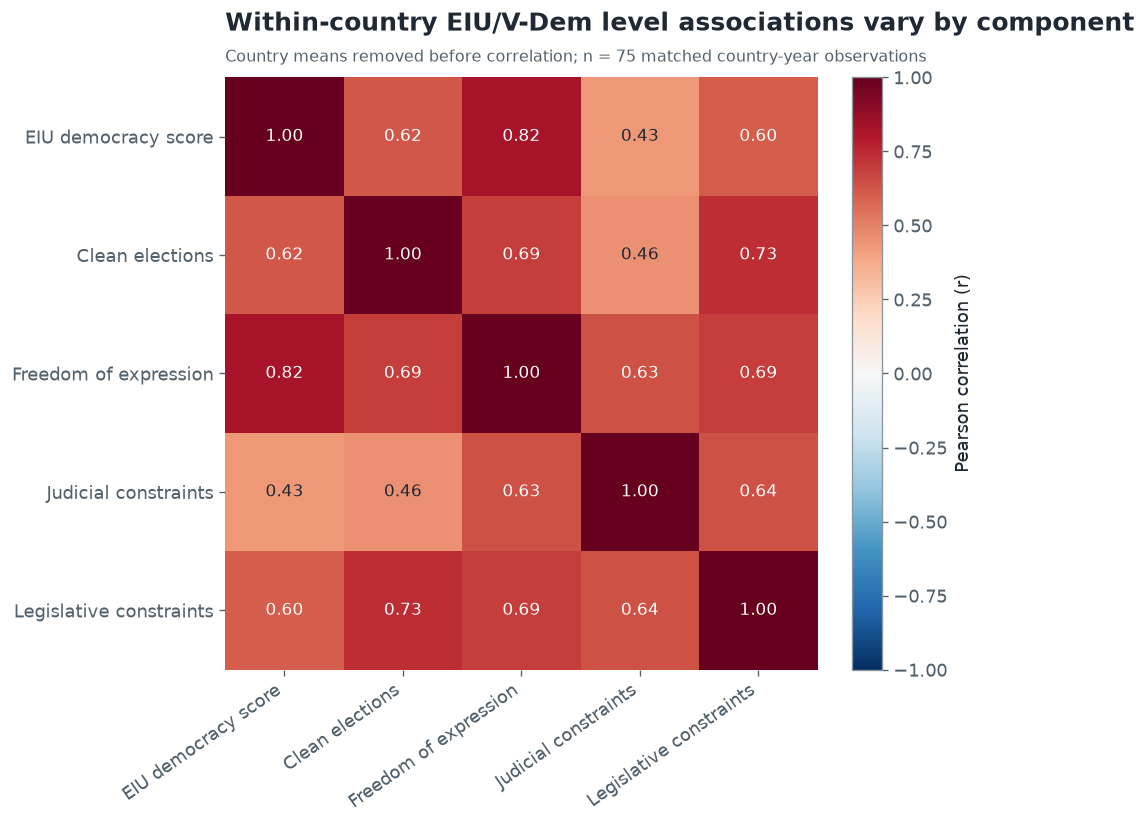

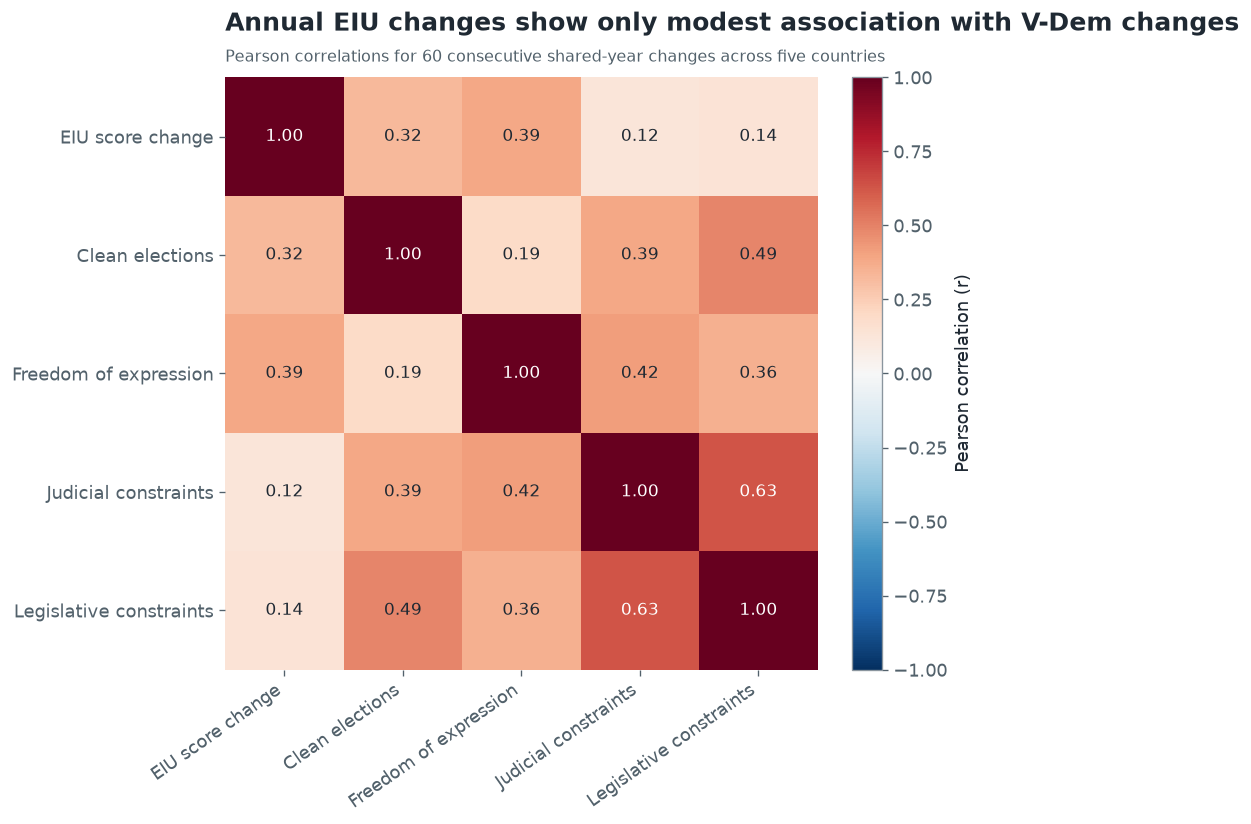

Saved correlation figures:
- figures/don_eiu_vdem_pooled_level_correlations.png (224,032 bytes)
- figures/don_eiu_vdem_within_country_correlations.png (228,021 bytes)
- figures/don_eiu_vdem_change_correlations.png (225,428 bytes)


In [16]:
def save_correlation_heatmap(
    correlation_table: pl.DataFrame,
    title: str,
    subtitle: str,
    output_name: str,
) -> Path:
    labels = correlation_table["measure"].to_list()
    values = correlation_table.select(labels).to_numpy().astype(float)

    # A fixed -1 to +1 color scale makes magnitudes comparable across all
    # matrices instead of allowing each figure to choose its own visual range.
    fig, ax = plt.subplots(figsize=(9, 7))
    image = ax.imshow(values, cmap="RdBu_r", vmin=-1, vmax=1)

    ax.set_xticks(range(len(labels)), labels, rotation=35, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    # Keep the measure labels but remove the global plotting grid so it does
    # not visually compete with the heatmap cells and their coefficients.
    ax.grid(False)
    ax.set_title(title, loc="left", fontsize=15, fontweight="bold", pad=28)
    ax.text(
        0, 1.02, subtitle, transform=ax.transAxes,
        ha="left", va="bottom", fontsize=9.5, color=MUTED,
    )

    # Print the coefficient in every cell so the heatmap remains useful in a
    # static report and does not require estimating values from color alone.
    for row_index in range(values.shape[0]):
        for column_index in range(values.shape[1]):
            text_color = "white" if abs(values[row_index, column_index]) >= 0.55 else INK
            ax.text(
                column_index, row_index, f"{values[row_index, column_index]:.2f}",
                ha="center", va="center", color=text_color, fontsize=10,
            )

    colorbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    colorbar.set_label("Pearson correlation (r)")
    ax.spines[:].set_visible(False)
    fig.tight_layout()

    output_path = FIGS / output_name
    fig.savefig(output_path, dpi=220, bbox_inches="tight", facecolor="white")
    plt.show()
    assert output_path.exists() and output_path.stat().st_size > 0
    return output_path


correlation_figure_paths = [
    save_correlation_heatmap(
        pooled_correlation,
        "EIU and V-Dem levels are positively associated across selected country-years",
        "Pooled Pearson correlations; n = 75 matched country-year observations",
        "don_eiu_vdem_pooled_level_correlations.png",
    ),
    save_correlation_heatmap(
        within_country_correlation,
        "Within-country EIU/V-Dem level associations vary by component",
        "Country means removed before correlation; n = 75 matched country-year observations",
        "don_eiu_vdem_within_country_correlations.png",
    ),
    save_correlation_heatmap(
        change_correlation,
        "Annual EIU changes show only modest association with V-Dem changes",
        "Pearson correlations for 60 consecutive shared-year changes across five countries",
        "don_eiu_vdem_change_correlations.png",
    ),
]

print("Saved correlation figures:")
for path in correlation_figure_paths:
    print(f"- {path} ({path.stat().st_size:,} bytes)")

### Correlation-check interpretation

A **level correlation with EIU** compares the score *levels* in all 75 matched country-year observations. For example, a positive clean-elections level correlation means that observations with a higher V-Dem clean-elections estimate also tended to have a higher EIU democracy score. It can reflect meaningful co-movement, but it can also be high because countries that generally score higher on one measure generally score higher on the other; it does not show that both measures rose or fell together in a particular year.

A **year-to-year change correlation** instead compares each country’s one-year difference with its V-Dem difference over the same consecutive year. A positive value means that, in years when the EIU score increased (or decreased), that V-Dem component tended to increase (or decrease) too. This is closer to the question of whether annual declines move together, but it remains descriptive and cannot establish that either measure caused the other.

The level correlations are positive but partly reflect stable differences between countries: pooled EIU correlations are **0.866** with clean elections, **0.737** with judicial constraints, **0.529** with freedom of expression, and **0.198** with legislative constraints. After removing each country's average level, the corresponding within-country correlations are **0.625**, **0.433**, **0.821**, and **0.605**.

The more direct year-to-year change correlations are weaker: **0.323** for clean elections, **0.386** for freedom of expression, **0.122** for judicial constraints, and **0.139** for legislative constraints. In plain terms, years when the EIU score changed downward were only modestly likely to be years when the V-Dem components changed downward too, especially for judicial and legislative constraints.

Therefore, this check supports a cautious statement about broad association in levels, but it does **not** establish a strong one-to-one relationship between annual EIU declines and annual V-Dem component declines. It also reinforces the measurement-overlap limitation: the two datasets may summarize related political information without responding identically to each year’s events.

In [17]:
# Surface a counterexample alongside the aggregate pattern so the conclusion
# does not imply every component moved in the same direction for every country.
mexico_clean_elections = vdem_comparison.filter(
    (pl.col("Code") == "MEX") & (pl.col("indicator") == "v2xel_frefair")
).row(0, named=True)
el_salvador_clear = country_component_summary.filter(
    pl.col("country") == "El Salvador"
)["clearly_separated_declines"].item()

print(
    "Contextualization result:\n"
    f"- {late_decline_count}/20 V-Dem component estimates declined from 2014 to 2022, "
    f"but only {clear_late_decline_count}/20 had non-overlapping coding bounds.\n"
    f"- El Salvador had {el_salvador_clear}/4 clearly separated component declines.\n"
    f"- Counterexample: Mexico's clean-elections estimate changed "
    f"{mexico_clean_elections['delta_14_22']:+.3f} after 2014.\n"
    "- The documentary evidence and component check support several plausible institutional "
    "pathways, not a causal decomposition of the EIU score."
)

Contextualization result:
- 19/20 V-Dem component estimates declined from 2014 to 2022, but only 9/20 had non-overlapping coding bounds.
- El Salvador had 4/4 clearly separated component declines.
- Counterexample: Mexico's clean-elections estimate changed +0.023 after 2014.
- The documentary evidence and component check support several plausible institutional pathways, not a causal decomposition of the EIU score.


# Preliminary finding: concentrated EIU declines coincided with broad, but uneven, institutional weakening

The five countries with the largest 2006–2022 EIU democracy-score declines in the selected 12-country North American comparison group, Nicaragua, Mexico, Guatemala, Haiti, and El Salvador, account for 8.53 of the group’s net 10.66-point decline, or about 80%. This makes them a meaningful set of cases for examining what accompanied the broader decline in this comparison group instead of a selection of dramatic examples.

Across these five cases, V-Dem’s 2014–2022 point estimates declined in 19 of 20 country-component comparisons covering clean elections, freedom of expression, judicial constraints on the executive, and legislative constraints on the executive. This pattern is consistent with the large EIU declines occurring alongside weakening in several institutional dimensions of democracy. However, it is not a uniform pattern, as the size of the estimated change differs across countries and components: only 9 of the 20 comparisons show a clear change because the two years’ plausible value ranges do not overlap, and Mexico’s clean-elections estimate increased slightly, by 0.023. Mexico's counterexample means that we should not read an EIU decline as evidence that every democratic institution weakened.

The matched-year correlation check reinforces this cautious reading. EIU and V-Dem levels are positively associated across the selected country-years, especially for clean elections and judicial constraints, but the correlations of year-to-year changes are modest. Put simply, the two measures tend to place stronger and weaker country-years in similar positions overall, but they do not reliably move together from one year to the next.

Our analysis does not show that V-Dem components caused EIU scores to fall. EIU and V-Dem are both expert-coded projects that assess related democratic concepts using much of the same public political record, so it's possible that their agreement may partly reflect overlapping measurement judgments instead of independent confirmation. We also limited our analysis to five high-decline cases and a selected comparison group which means we cannot establish, therefore, that the same pattern applies to all countries or all forms of democratic decline.

## What this adds

The five declines do not share one sufficient explanation. Nicaragua and El Salvador show concentrated restrictions on competition, checks, and liberties; Guatemala shows a slower weakening of judicial and anti-impunity institutions; Haiti combines an electoral and institutional vacuum with loss of state capacity; and Mexico shows pressure on checks, media, and civilian governance alongside a V-Dem clean-elections counterexample.

The independent check is directionally consistent but more uncertain than a simple event narrative would suggest: 19 of 20 V-Dem country-component point estimates are lower in 2022 than in 2014, while only 9 of 20 have non-overlapping coding bounds under the conservative rule. This supports further investigation of institutional dimensions, but it cannot determine which development influenced a specific EIU change or by how much. EIU and V-Dem are both expert-coded measures with overlapping concepts, so agreement may partly reflect shared measurement judgments.


The matched-year correlation check tempers that conclusion. Pooled level correlations with EIU are strongest for clean elections (0.866) and judicial constraints (0.737), but correlations of consecutive-year changes are only 0.323, 0.386, 0.122, and 0.139 for clean elections, expression, judicial constraints, and legislative constraints respectively. The evidence therefore supports related cross-country levels more than a strong year-by-year one-to-one movement.

### Analyses not promoted to the main story

- A broad screen of inflation, migration, growth, crime, or neighboring-country conditions was not run. With five selected cases and many candidate predictors, it would invite post-hoc correlations without identifying causes.
- The unexplained 2018 El Salvador drop remains visible rather than being assigned a later Bukele-era explanation.
- Haiti's 2018 rebound and Mexico's post-2014 V-Dem clean-elections increase are retained as counterevidence to a uniform decline mechanism.
- No new polished figure or replacement finding is produced here; P2 contextualizes the existing P1 result.

### Data source and references

V-Dem data come from the V-Dem Institute's official [`vdemdata` V13 tag](https://github.com/vdeminstitute/vdemdata/tree/V13), published March 2023, accessed November 17, 2026, and distributed under [CC BY-SA 4.0](https://www.v-dem.net/about/faq/). The cached RData file is ignored by Git; the notebook pins its URL and SHA-256 and extracts only the needed rows at runtime. Variable definitions and uncertainty fields are from the [V-Dem v13 codebook](https://www.v-dem.net/documents/24/codebook_v13.pdf). Documentary sources are linked in each country dossier above.

# Daniel's Narrative Work

The cells in this section are preserved from `daniel_narrative.ipynb`.


# Narrative analysis: hybrid-regime variation (Daniel)

**Research question 2 (second half):** do hybrid regimes show greater annual score variation?

This notebook makes every number and the figure in my section of `NARRATIVE.md`. It reads the tables made by `build_data.py`, and runs that script first if the tables are missing.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path("..")
DATA = ROOT / "data"
FIGS = Path("figures")
FIGS.mkdir(exist_ok=True)

if not (DATA / "rq2_changes.csv").exists():
    subprocess.run([sys.executable, "build_data.py"], cwd=ROOT, check=True)

changes = pd.read_csv(DATA / "rq2_changes.csv")
panel = pd.read_csv(DATA / "panel_country.csv")
rng = np.random.default_rng(418)

REGIMES = ["Authoritarian", "Hybrid regime", "Flawed democracy", "Full democracy"]
print(changes.shape, changes["year"].min(), "to", changes["year"].max())

(2004, 9) 2011 to 2022


## 1. Measure: how much a country's score moves in a typical year

`rq2_changes.csv` has 2,004 one-year changes (2010 to 2022, back-to-back years only). For each country I take the **mean absolute one-year change**, so a +0.3 and a -0.3 both count as 0.3 points of movement. Each country gets one number, so countries with more volatile years can't be counted twice.

Countries are grouped by their **EIU regime in 2010**, the first year of the annual series, so the grouping is fixed before any of the changes happen.

In [2]:
changes["abs_change"] = changes["score_change"].abs()
start = panel[panel["year"] == 2010].set_index("country_code")


def by_country(df):
    out = df.groupby("country_code").agg(
        mean_abs_change=("abs_change", "mean"),
        net_change=("score_change", "sum"),
        big_moves=("abs_change", lambda s: (s >= 0.5).sum()),
    )
    out["regime_2010"] = start["regime"]
    out["score_2010"] = start["democracy_score"]
    out["country_name"] = start["country_name"]
    return out


countries = by_country(changes)


def boot_median(values, n=10000):
    values = np.asarray(values)
    meds = [np.median(rng.choice(values, len(values))) for _ in range(n)]
    return np.percentile(meds, [2.5, 97.5])


summary = []
for regime in REGIMES:
    vals = countries.loc[countries["regime_2010"] == regime, "mean_abs_change"]
    low, high = boot_median(vals)
    summary.append({"regime_2010": regime, "countries": len(vals), "median": vals.median(),
                    "ci_low": low, "ci_high": high})
summary = pd.DataFrame(summary).set_index("regime_2010")
print(summary.round(3))

                  countries  median  ci_low  ci_high
regime_2010                                         
Authoritarian            57   0.112   0.088    0.128
Hybrid regime            31   0.150   0.107    0.185
Flawed democracy         53   0.096   0.078    0.116
Full democracy           26   0.063   0.050    0.076


In [3]:
hybrid = countries.loc[countries["regime_2010"] == "Hybrid regime", "mean_abs_change"]
others = countries.loc[countries["regime_2010"] != "Hybrid regime", "mean_abs_change"]

diffs = [np.median(rng.choice(hybrid.values, len(hybrid))) - np.median(rng.choice(others.values, len(others)))
         for _ in range(10000)]
print(f"hybrid median {hybrid.median():.3f} vs all others {others.median():.3f}; "
      f"difference {hybrid.median() - others.median():.3f}, 95% bootstrap CI {np.percentile(diffs, [2.5, 97.5]).round(3)}")
print("full democracy median:", round(summary.loc["Full democracy", "median"], 3),
      "| hybrid / full ratio:", round(hybrid.median() / summary.loc["Full democracy", "median"], 1))

for regime in ["Authoritarian", "Flawed democracy", "Full democracy"]:
    other = countries.loc[countries["regime_2010"] == regime, "mean_abs_change"]
    test = stats.mannwhitneyu(hybrid, other, alternative="two-sided")
    print(f"Mann-Whitney U, hybrid vs {regime}: U = {test.statistic:.0f}, two-sided p = {test.pvalue:.4f}")
test = stats.mannwhitneyu(hybrid, others, alternative="two-sided")
print(f"Mann-Whitney U, hybrid vs all others: U = {test.statistic:.0f}, two-sided p = {test.pvalue:.5f}")

hybrid median 0.150 vs all others 0.090; difference 0.060, 95% bootstrap CI [0.011 0.098]
full democracy median: 0.063 | hybrid / full ratio: 2.4
Mann-Whitney U, hybrid vs Authoritarian: U = 1105, two-sided p = 0.0535
Mann-Whitney U, hybrid vs Flawed democracy: U = 1172, two-sided p = 0.0012
Mann-Whitney U, hybrid vs Full democracy: U = 752, two-sided p = 0.0000
Mann-Whitney U, hybrid vs all others: U = 3030, two-sided p = 0.00015


## 2. Direction: is the extra movement up or down?

In [4]:
print(countries.groupby("regime_2010")["net_change"].agg(
    median_net_change="median", share_declined=lambda s: (s < 0).mean()).reindex(REGIMES).round(3))

big = changes[(changes["regime_previous"] == "Hybrid regime") & (changes["abs_change"] >= 0.5)]
print(f"\nOne-year moves of 0.5+ points while hybrid: {len(big)}, of which declines: {(big['score_change'] < 0).sum()}")
print(big.sort_values("score_change")[["country_name", "year", "score_change"]].head(8).to_string(index=False))

share_big = changes.groupby("regime_previous")["abs_change"].apply(lambda s: (s >= 0.5).mean()).reindex(REGIMES)
print("\nShare of one-year changes that are 0.5+ points, by regime that year:")
print((100 * share_big).round(1))

                  median_net_change  share_declined
regime_2010                                        
Authoritarian                 -0.06           0.526
Hybrid regime                 -0.42           0.581
Flawed democracy              -0.01           0.528
Full democracy                -0.07           0.538

One-year moves of 0.5+ points while hybrid: 37, of which declines: 22
country_name  year  score_change
       Egypt  2013         -1.29
   Nicaragua  2018         -1.03
       Libya  2014         -1.02
        Mali  2020         -0.99
     Bolivia  2019         -0.86
       Nepal  2021         -0.81
   Venezuela  2017         -0.81
       Haiti  2021         -0.74

Share of one-year changes that are 0.5+ points, by regime that year:
regime_previous
Authoritarian       6.8
Hybrid regime       8.4
Flawed democracy    2.0
Full democracy      0.0
Name: abs_change, dtype: float64


## 3. Trying to break the finding

Alternative explanations, and the check run against each:

1. **A few coups or revolutions drive it.** Drop every country with any single one-year move of 1.5+ points, then redo the comparison.
2. **2020 and 2021 pandemic scoring.** EIU marked down civil liberties during lockdowns. Drop those two years.
3. **It depends on the time window.** Split into 2011-2016 and 2017-2022.
4. **It's just the middle of the scale.** Hybrid is the 4-6 band, so it has room to move both ways, while full democracies sit near the 10 ceiling. Look at variation by 2010 score instead of regime label, and compare hybrid with flawed democracies, the other mid-scale group.

In [5]:
def compare(df, label):
    c = by_country(df)
    h = c.loc[c["regime_2010"] == "Hybrid regime", "mean_abs_change"]
    row = {"check": label}
    for regime in REGIMES:
        row[regime] = c.loc[c["regime_2010"] == regime, "mean_abs_change"].median()
    for regime in ["Authoritarian", "Flawed democracy"]:
        row[f"p vs {regime}"] = stats.mannwhitneyu(h, c.loc[c["regime_2010"] == regime, "mean_abs_change"],
                                                   alternative="two-sided").pvalue
    row["p vs all others"] = stats.mannwhitneyu(h, c.loc[c["regime_2010"] != "Hybrid regime", "mean_abs_change"],
                                                alternative="two-sided").pvalue
    return row


shock_countries = changes.groupby("country_code")["abs_change"].max().loc[lambda s: s >= 1.5].index
print("Shock countries dropped:", sorted(changes.loc[changes["country_code"].isin(shock_countries), "country_name"].unique()))

checks = pd.DataFrame([
    compare(changes, "all years (main result)"),
    compare(changes[~changes["country_code"].isin(shock_countries)], "drop shock countries"),
    compare(changes[~changes["year"].isin([2020, 2021])], "drop 2020 and 2021"),
    compare(changes[changes["year"] <= 2016], "2011-2016 only"),
    compare(changes[changes["year"] >= 2017], "2017-2022 only"),
]).set_index("check")
with pd.option_context("display.width", 200):
    print(checks.round(3))

Shock countries dropped: ['Afghanistan', 'Fiji', 'Libya', 'Myanmar', 'Thailand', 'Tunisia']
                         Authoritarian  Hybrid regime  Flawed democracy  Full democracy  p vs Authoritarian  p vs Flawed democracy  p vs all others
check                                                                                                                                              
all years (main result)          0.112          0.150             0.096           0.063               0.054                  0.001            0.000
drop shock countries             0.111          0.150             0.095           0.063               0.006                  0.001            0.000
drop 2020 and 2021               0.112          0.132             0.080           0.056               0.139                  0.001            0.000
2011-2016 only                   0.085          0.110             0.080           0.038               0.707                  0.039            0.024
2017-2022 only      

In [6]:
bins = pd.cut(countries["score_2010"], [0, 2, 3, 4, 5, 6, 7, 8, 10])
print(countries.groupby(bins, observed=True)["mean_abs_change"].agg(countries="size", median="median").round(3))
rho = stats.spearmanr(countries["mean_abs_change"], (countries["score_2010"] - 5).abs())
print(f"\nSpearman correlation between movement and distance from a score of 5: rho = {rho.statistic:.2f}, p = {rho.pvalue:.1e}")

            countries  median
score_2010                   
(0, 2]             11   0.085
(2, 3]             17   0.104
(3, 4]             29   0.126
(4, 5]             12   0.168
(5, 6]             19   0.118
(6, 7]             30   0.115
(7, 8]             23   0.078
(8, 10]            26   0.063

Spearman correlation between movement and distance from a score of 5: rho = -0.48, p = 3.7e-11


## 4. Figure

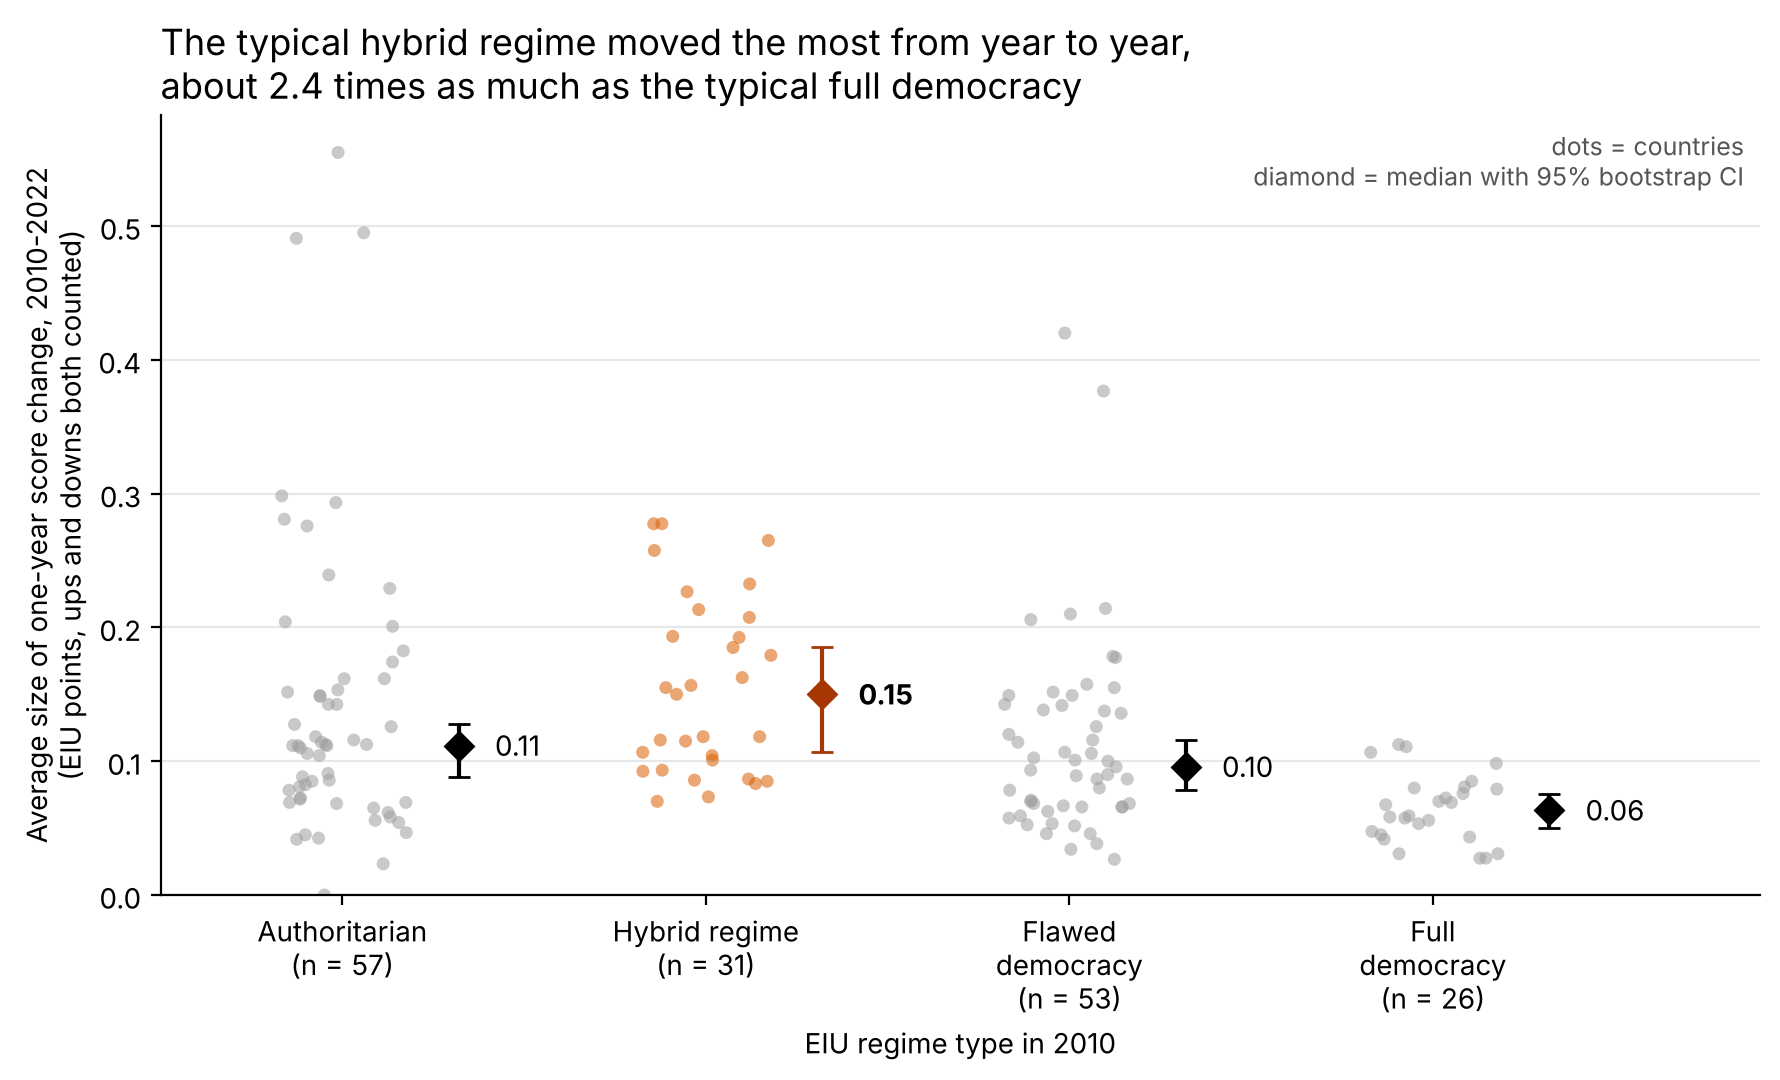

In [7]:
colors = {"Authoritarian": "#9e9e9e", "Hybrid regime": "#d95f02", "Flawed democracy": "#9e9e9e", "Full democracy": "#9e9e9e"}
labels = {"Authoritarian": "Authoritarian", "Hybrid regime": "Hybrid regime",
          "Flawed democracy": "Flawed\ndemocracy", "Full democracy": "Full\ndemocracy"}

fig, ax = plt.subplots(figsize=(9, 5.5))
for i, regime in enumerate(REGIMES):
    vals = countries.loc[countries["regime_2010"] == regime, "mean_abs_change"].to_numpy()
    jitter = rng.uniform(-0.18, 0.18, len(vals))
    ax.scatter(np.full(len(vals), i) + jitter, vals, s=22, color=colors[regime], alpha=0.55, edgecolor="none")
    row = summary.loc[regime]
    ax.errorbar(i + 0.32, row["median"], yerr=[[row["median"] - row["ci_low"]], [row["ci_high"] - row["median"]]],
                fmt="D", color="black" if regime != "Hybrid regime" else "#a63603", markersize=7, capsize=4, linewidth=1.5)
    ax.text(i + 0.42, row["median"], f"{row['median']:.2f}", va="center", fontsize=10,
            fontweight="bold" if regime == "Hybrid regime" else "normal")

ax.set_xticks(range(len(REGIMES)))
ax.set_xticklabels([f"{labels[r]}\n(n = {int(summary.loc[r, 'countries'])})" for r in REGIMES])
ax.set_xlim(-0.5, 3.9)
ax.set_ylim(0, None)
ax.set_xlabel("EIU regime type in 2010")
ax.set_ylabel("Average size of one-year score change, 2010-2022\n(EIU points, ups and downs both counted)")
ax.set_title("The typical hybrid regime moved the most from year to year,\nabout 2.4 times as much as the typical full democracy", loc="left", fontsize=13)
ax.text(0.99, 0.98, "dots = countries\ndiamond = median with 95% bootstrap CI", transform=ax.transAxes,
        ha="right", va="top", fontsize=9, color="#555555")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(FIGS / "daniel_hybrid_variation.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Analyses that did not make it into the story

- **Geography.** The repository has no country-to-region mapping (see `DATASHEET.md`), so I could not test whether the pattern holds within each continent without adding a new, undocumented source. This is the next check to run.
- **Change-level comparison.** Grouping each one-year change by the regime that year (instead of fixing the regime in 2010) gives the same order: hybrid 0.16, authoritarian 0.14, flawed 0.10, full 0.06. I left it out because one country can switch groups, and the country-level version is cleaner.
- **Required voting.** We have no compulsory-voting variable in either dataset, so I did not test it.



# Sai (Kam)'s Narrative Work

The cells in this section are preserved from `Untitled.ipynb`.


In [3]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df_merged = pd.read_csv("../hdi-ihdi-democracy-by-country.csv")
df_eiu = pd.read_csv("../democracy-index-eiu.csv")

print("Merged shape:", df_merged.shape)
print("Columns:", df_merged.columns.tolist())
display(df_merged.head())

Merged shape: (194, 8)
Columns: ['country_code', 'Rank', 'HDI', 'IHDI', 'Country', 'Year', 'democracy_eiu', 'democracy_eiu_normalized']


,country_code,Rank,HDI,IHDI,Country,Year,democracy_eiu,democracy_eiu_normalized
0,CHE,1.0,0.967,0.891,Switzerland,2023,9.14,0.914
1,NOR,2.0,0.966,0.903,Norway,2023,9.81,0.981
2,ISL,3.0,0.959,0.91,Iceland,2023,9.45,0.945
3,HKG,4.0,0.956,0.84,Hong Kong,2023,5.24,0.524
4,DNK,5.0,0.952,0.898,Denmark,2023,9.28,0.928


In [7]:
# 1. Convert HDI, IHDI, and democracy_eiu to numeric (turns ".." strings into NaN)
df_merged["HDI"] = pd.to_numeric(df_merged["HDI"], errors="coerce")
df_merged["IHDI"] = pd.to_numeric(df_merged["IHDI"], errors="coerce")
df_merged["democracy_eiu"] = pd.to_numeric(df_merged["democracy_eiu"], errors="coerce")

# 2. Extract 2022 EIU scores from df_eiu and merge by ISO3 Code so we have exact 2022 EIU scores
eiu_2022 = (
    df_eiu[df_eiu["Year"] == 2022][["Code", "Democracy score"]]
    .dropna(subset=["Code"])
    .rename(columns={"Code": "country_code", "Democracy score": "democracy_eiu_2022"})
)
df_analysis = df_merged.merge(eiu_2022, on="country_code", how="left")

print("--- Missingness Audit Across All 194 Countries in df_merged ---")
print(df_analysis[["democracy_eiu_2022", "democracy_eiu", "HDI", "IHDI"]].isna().sum())

# Countries with 2022 EIU & HDI, but missing IHDI (stored as ".." in raw UNDP table)
missing_ihdi = df_analysis[
    df_analysis["democracy_eiu_2022"].notna() & df_analysis["HDI"].notna() & df_analysis["IHDI"].isna()
]
print(f"\nCountries with 2022 EIU & HDI but MISSING IHDI (n={len(missing_ihdi)}):")
print(missing_ihdi[["Country", "democracy_eiu_2022", "HDI"]].sort_values("HDI", ascending=False).to_string(index=False))

# Countries with HDI, but missing 2022 EIU score (mostly microstates, Gulf states, or conflict zones)
missing_eiu = df_analysis[df_analysis["HDI"].notna() & df_analysis["democracy_eiu_2022"].isna()]
print(f"\nCountries with HDI but MISSING 2022 EIU score (n={len(missing_eiu)}):")
print(missing_eiu[["Country", "HDI", "IHDI"]].sort_values("HDI", ascending=False).head(15).to_string(index=False))

# 3. Clean analytical sample using 2022 EIU scores & Threshold 6.0 Comparison
df_clean = df_analysis.dropna(subset=["democracy_eiu_2022", "HDI"]).copy()
df_clean["above_6"] = (df_clean["democracy_eiu_2022"] >= 6.0).astype(int)
df_clean["regime_group"] = np.where(
    df_clean["above_6"] == 1,
    "Score >= 6.0 (Democracies)",
    "Score < 6.0 (Hybrid / Authoritarian)"
)
df_clean["inequality_loss"] = df_clean["HDI"] - df_clean["IHDI"]

print(f"\n--- Group Averages & 95% CIs Around 2022 Democracy Score = 6.0 (n={len(df_clean)}) ---")
for metric in ["HDI", "IHDI", "inequality_loss"]:
    print(f"\nMetric: {metric}")
    for grp, sub in df_clean.dropna(subset=[metric]).groupby("regime_group"):
        mean = sub[metric].mean()
        se = stats.sem(sub[metric])
        ci_low, ci_high = stats.t.interval(0.95, len(sub) - 1, loc=mean, scale=se)
        print(f"  {grp} (n={len(sub)}): mean = {mean:.3f} (95% CI: [{ci_low:.3f}, {ci_high:.3f}])")

--- Missingness Audit Across All 194 Countries in df_merged ---
democracy_eiu_2022    28
democracy_eiu         46
HDI                    1
IHDI                  29
dtype: int64

Countries with 2022 EIU & HDI but MISSING IHDI (n=15):
             Country  democracy_eiu_2022   HDI
             Bahrain                2.52 0.888
               Qatar                3.65 0.875
        Saudi Arabia                2.08 0.875
              Kuwait                3.83 0.847
 Trinidad and Tobago                7.16 0.814
                Cuba                2.65 0.764
               Libya                2.06 0.746
        Turkmenistan                1.66 0.744
              Guyana                6.34 0.742
          Uzbekistan                2.12 0.727
             Lebanon                3.64 0.723
            Suriname                6.95 0.690
   Equatorial Guinea                1.92 0.650
Syrian Arab Republic                1.43 0.557
             Eritrea                2.03 0.493

Countries with

In [9]:
# 1. Pearson & Spearman correlations on the common sample (countries with 2022 EIU, HDI, AND IHDI)
df_common = df_clean.dropna(subset=["IHDI"]).copy()
print(f"--- Common Sample Correlations (n={len(df_common)}) ---")
for metric in ["HDI", "IHDI", "inequality_loss"]:
    r, p_r = stats.pearsonr(df_common["democracy_eiu_2022"], df_common[metric])
    rho, p_rho = stats.spearmanr(df_common["democracy_eiu_2022"], df_common[metric])
    print(f"{metric} vs. 2022 Democracy: Pearson r = {r:.3f} (p={p_r:.2e}), Spearman rho = {rho:.3f} (p={p_rho:.2e})")

# 2. Piecewise / Threshold Regression around 6.0 (HC3 robust standard errors)
df_common["dem_centered"] = df_common["democracy_eiu_2022"] - 6.0

mod_hdi = smf.ols("HDI ~ dem_centered * above_6", data=df_common).fit(cov_type="HC3")
mod_ihdi = smf.ols("IHDI ~ dem_centered * above_6", data=df_common).fit(cov_type="HC3")

print("\n=== Piecewise Regression Around 6.0: HDI (Common Sample) ===")
print(mod_hdi.summary().tables[1])

print("\n=== Piecewise Regression Around 6.0: IHDI (Common Sample) ===")
print(mod_ihdi.summary().tables[1])

# 3. Break Attempt 1: High-HDI (>=0.80) countries below score 6.0 (e.g., wealthy autocracies / petro-states)
high_hdi_autocracies = df_clean[(df_clean["above_6"] == 0) & (df_clean["HDI"] >= 0.80)]
print(f"\n--- High-HDI (>=0.80) Countries Below Score 6.0 (n={len(high_hdi_autocracies)}) ---")
print(high_hdi_autocracies[["Country", "democracy_eiu_2022", "HDI", "IHDI"]].sort_values("HDI", ascending=False).to_string(index=False))

# 4. Break Attempt 2: Check whether using 2023 EIU scores (from df_merged) changes the correlation/jump
r_2023, _ = stats.pearsonr(df_common["democracy_eiu"], df_common["HDI"])
r_ihdi_2023, _ = stats.pearsonr(df_common["democracy_eiu"], df_common["IHDI"])
print(f"\n--- Year Sensitivity Check (2023 EIU vs 2022 EIU on Common Sample) ---")
print(f"2023 EIU vs HDI: r = {r_2023:.3f} | 2023 EIU vs IHDI: r = {r_ihdi_2023:.3f}")

--- Common Sample Correlations (n=150) ---
HDI vs. 2022 Democracy: Pearson r = 0.698 (p=2.91e-23), Spearman rho = 0.713 (p=1.50e-24)
IHDI vs. 2022 Democracy: Pearson r = 0.671 (p=6.16e-21), Spearman rho = 0.688 (p=2.55e-22)
inequality_loss vs. 2022 Democracy: Pearson r = -0.433 (p=3.07e-08), Spearman rho = -0.445 (p=1.15e-08)

=== Piecewise Regression Around 6.0: HDI (Common Sample) ===
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                0.6669      0.026     25.646      0.000       0.616       0.718
dem_centered             0.0191      0.010      1.844      0.065      -0.001       0.039
above_6                  0.0646      0.034      1.890      0.059      -0.002       0.132
dem_centered:above_6     0.0490      0.014      3.571      0.000       0.022       0.076

=== Piecewise Regression Around 6.0: IHDI (Common Sample) ===
             

=== Full Sample HDI (n=165) vs. Excluding High-HDI (<6.0) Outliers (n=153) ===
All Countries (n=165):
  Slope < 6.0: 0.011 (p=0.244) | Jump at 6.0: +0.062 (p=0.065) | Slope change >= 6.0: +0.058 (p=0.000)
Excl. High-HDI <6.0 Outliers (n=153):
  Slope < 6.0: 0.015 (p=0.087) | Jump at 6.0: +0.085 (p=0.007) | Slope change >= 6.0: +0.054 (p=0.000)


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


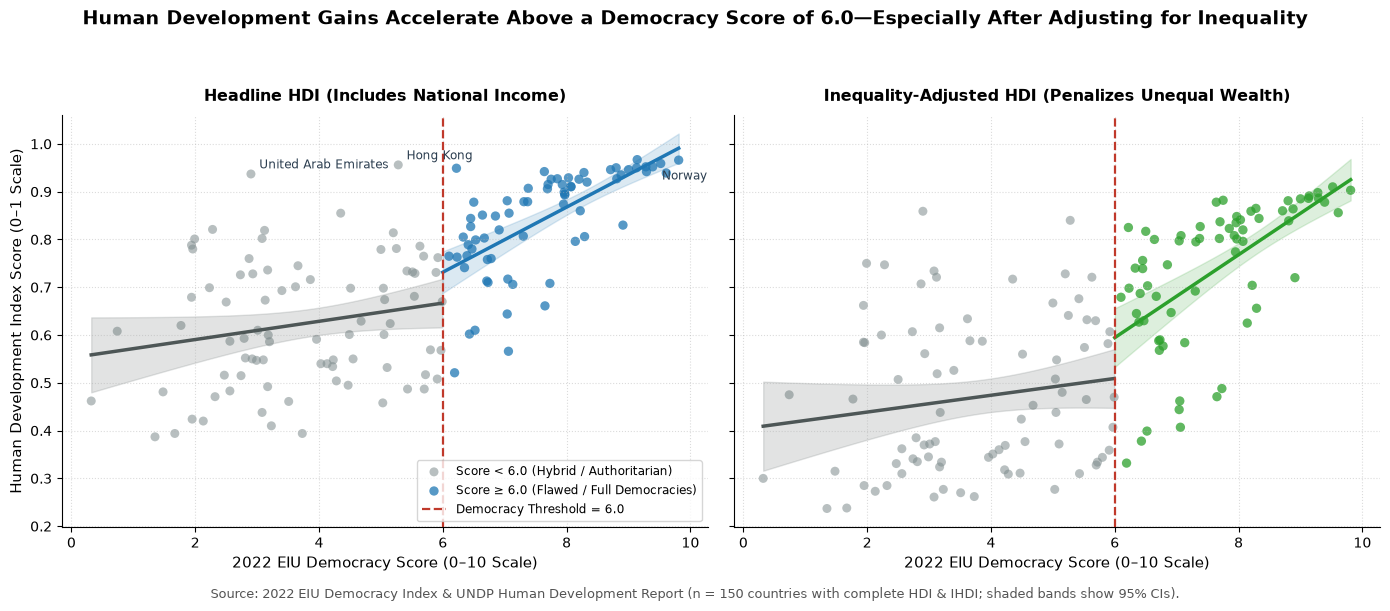

In [10]:
# 1. Exact Break Attempt: Compare piecewise slopes WITH vs. WITHOUT the 12 high-HDI (<6.0) outliers
df_clean["dem_centered"] = df_clean["democracy_eiu_2022"] - 6.0
df_no_rich_aut = df_clean[~((df_clean["above_6"] == 0) & (df_clean["HDI"] >= 0.80))].copy()

mod_hdi_all = smf.ols("HDI ~ dem_centered * above_6", data=df_clean).fit(cov_type="HC3")
mod_hdi_no_out = smf.ols("HDI ~ dem_centered * above_6", data=df_no_rich_aut).fit(cov_type="HC3")

print("=== Full Sample HDI (n=165) vs. Excluding High-HDI (<6.0) Outliers (n=153) ===")
for name, m in [("All Countries (n=165)", mod_hdi_all), ("Excl. High-HDI <6.0 Outliers (n=153)", mod_hdi_no_out)]:
    b_below = m.params["dem_centered"]
    p_below = m.pvalues["dem_centered"]
    b_jump = m.params["above_6"]
    p_jump = m.pvalues["above_6"]
    b_kink = m.params["dem_centered:above_6"]
    p_kink = m.pvalues["dem_centered:above_6"]
    print(f"{name}:")
    print(f"  Slope < 6.0: {b_below:.3f} (p={p_below:.3f}) | Jump at 6.0: +{b_jump:.3f} (p={p_jump:.3f}) | Slope change >= 6.0: +{b_kink:.3f} (p={p_kink:.3f})")

# 2. Create Polished Story-Titled Figure
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

panels = [
    ("HDI", "Headline HDI (Includes National Income)", mod_hdi, "#1f77b4", "n = 150 (Common Sample)"),
    ("IHDI", "Inequality-Adjusted HDI (Penalizes Unequal Wealth)", mod_ihdi, "#2ca02c", "n = 150 (15 Countries Missing IHDI, incl. 4 Gulf States)")
]

for ax, (col, subtitle, model, color, note) in zip(axes, panels):
    # Scatter points
    below = df_common[df_common["above_6"] == 0]
    above = df_common[df_common["above_6"] == 1]
    
    ax.scatter(below["democracy_eiu_2022"], below[col], alpha=0.55, color="#7f8c8d", edgecolors="none", s=42, label="Score < 6.0 (Hybrid / Authoritarian)")
    ax.scatter(above["democracy_eiu_2022"], above[col], alpha=0.75, color=color, edgecolors="none", s=45, label="Score ≥ 6.0 (Flawed / Full Democracies)")
    
    # Piecewise regression lines + 95% CI bands
    for grp_val, x_grid in [(0, np.linspace(df_common["democracy_eiu_2022"].min(), 5.99, 100)),
                            (1, np.linspace(6.0, df_common["democracy_eiu_2022"].max(), 100))]:
        pred_df = pd.DataFrame({"dem_centered": x_grid - 6.0, "above_6": grp_val})
        pred = model.get_prediction(pred_df).summary_frame(alpha=0.05)
        line_col = "#4d5656" if grp_val == 0 else color
        ax.plot(x_grid, pred["mean"], color=line_col, linewidth=2.5)
        ax.fill_between(x_grid, pred["mean_ci_lower"], pred["mean_ci_upper"], color=line_col, alpha=0.16)
    
    # Threshold vertical line at 6.0
    ax.axvline(6.0, color="#c0392b", linestyle="--", linewidth=1.6, label="Democracy Threshold = 6.0")
    ax.set_title(subtitle, fontsize=11.5, fontweight="bold", pad=10)
    ax.set_xlabel("2022 EIU Democracy Score (0–10 Scale)", fontsize=10.5)
    ax.grid(True, linestyle=":", alpha=0.45)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Annotate notable high-income autocratic outliers in HDI panel
outliers_to_label = ["Hong Kong", "United Arab Emirates", "Norway"]
for country in outliers_to_label:
    row = df_common[df_common["Country"] == country]
    if not row.empty:
        x_val = row["democracy_eiu_2022"].values[0]
        y_val = row["HDI"].values[0]
        offset = (-12, -14) if country == "Norway" else (6, 4)
        axes[0].annotate(country, (x_val, y_val), xytext=offset, textcoords="offset points", fontsize=8.5, color="#2c3e50", fontweight="medium")

axes[0].set_ylabel("Human Development Index Score (0–1 Scale)", fontsize=10.5)
axes[0].legend(loc="lower right", frameon=True, fontsize=8.8)

fig.suptitle(
    "Human Development Gains Accelerate Above a Democracy Score of 6.0—Especially After Adjusting for Inequality",
    fontsize=13.5, fontweight="bold", y=0.99
)
fig.text(
    0.5, 0.01,
    "Source: 2022 EIU Democracy Index & UNDP Human Development Report (n = 150 countries with complete HDI & IHDI; shaded bands show 95% CIs).",
    ha="center", fontsize=9, color="#555555"
)

plt.tight_layout(rect=[0, 0.03, 1, 0.94])
plt.savefig("fig_sai_democracy_hdi_threshold.png", dpi=300, bbox_inches="tight")
plt.show()